# 🐟 Intelligent Fish Feeding System — Full Pipeline
> **Project:** Design and implementation of an intelligent fish feeding system  
> **School:** SESAME — École Supérieure Privée des Sciences Appliquées et de Management  

| # | Section |
|---|--------|
| 1 | Imports & Config |
| 2 | Data Loading |
| 3 | Data Audit |
| 4 | Exploratory Data Analysis |
| 5 | Data Cleaning |
| 6 | Feature Engineering |
| 7 | Feature Selection |
| 8 | Preprocessing & Splits |
| 9 | Model Training |
| 10 | Model Comparison |
| 11 | Hyperparameter Tuning |
| 12 | SHAP Explainability |
| 13 | Recommendation Engine |
| 14 | Final Test Evaluation & Save |

---
## 1. 📦 Imports & Config

In [1]:
import os, glob, zipfile, warnings, json, time, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import zscore, skew

# ── Sklearn ───────────────────────────────────────────────────────────────────
from sklearn.linear_model  import LinearRegression, Ridge, Lasso, LogisticRegression
from sklearn.tree          import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble      import (RandomForestRegressor, RandomForestClassifier,
                                   GradientBoostingRegressor, GradientBoostingClassifier,
                                   ExtraTreesRegressor, ExtraTreesClassifier)
from sklearn.neighbors     import KNeighborsRegressor, KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, LabelEncoder
from sklearn.impute        import SimpleImputer, KNNImputer
from sklearn.feature_selection import (mutual_info_classif, mutual_info_regression,
                                        VarianceThreshold)
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                              accuracy_score, f1_score, classification_report,
                              confusion_matrix, roc_auc_score, ConfusionMatrixDisplay)

# ── XGBoost ───────────────────────────────────────────────────────────────────
try:
    import xgboost as xgb;  XGB_OK = True;  print('✅  XGBoost', xgb.__version__)
except ImportError:
    XGB_OK = False;          print('⚠️  XGBoost not found')

# ── LightGBM ──────────────────────────────────────────────────────────────────
try:
    import lightgbm as lgb; LGB_OK = True;  print('✅  LightGBM', lgb.__version__)
except ImportError:
    LGB_OK = False;          print('⚠️  LightGBM not found')

# ── PyTorch ───────────────────────────────────────────────────────────────────
try:
    import torch, torch.nn as nn, torch.optim as optim
    from torch.utils.data import DataLoader, TensorDataset
    TORCH_OK = True
    DEVICE   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f'✅  PyTorch {torch.__version__} | device={DEVICE}')
except ImportError:
    TORCH_OK = False;        print('⚠️  PyTorch not found')

# ── Optuna ────────────────────────────────────────────────────────────────────
try:
    import optuna; optuna.logging.set_verbosity(optuna.logging.WARNING)
    OPTUNA_OK = True;        print('✅  Optuna', optuna.__version__)
except ImportError:
    OPTUNA_OK = False;       print('⚠️  Optuna not found  (pip install optuna)')

# ── SHAP ──────────────────────────────────────────────────────────────────────
try:
    import shap; SHAP_OK = True; print('✅  SHAP', shap.__version__)
except ImportError:
    SHAP_OK = False;         print('⚠️  SHAP not found  (pip install shap)')

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', '{:.4f}'.format)

PALETTE  = ['#1565C0','#2E7D32','#F57F17','#AD1457','#6A1B9A','#00838F','#E64A19']
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
sns.set_palette(PALETTE)

# ── Output dirs ───────────────────────────────────────────────────────────────
OUT_DIR = '/kaggle/working'
os.makedirs(OUT_DIR, exist_ok=True)
print('\n✅  All libraries loaded.')

✅  XGBoost 3.2.0
✅  LightGBM 4.6.0
✅  PyTorch 2.10.0+cu128 | device=cuda
✅  Optuna 4.8.0
✅  SHAP 0.50.0

✅  All libraries loaded.


---
## 2. 📂 Data Loading

In [2]:
INPUT_DIR = '/kaggle/input'

# ── Unzip any archives ────────────────────────────────────────────────────────
for zp in glob.glob(os.path.join(INPUT_DIR, '**', '*.zip'), recursive=True):
    dest = os.path.splitext(zp)[0]
    os.makedirs(dest, exist_ok=True)
    with zipfile.ZipFile(zp, 'r') as z:
        z.extractall(dest)
    print(f'📦  Extracted {zp}')

# ── Find all CSVs ─────────────────────────────────────────────────────────────
csv_files = sorted(glob.glob(os.path.join(INPUT_DIR, '**', '*.csv'), recursive=True))
print(f'\n🗂  Found {len(csv_files)} CSV file(s):')
for f in csv_files:
    print(f'   • {f}  ({os.path.getsize(f)/1e3:.1f} KB)')


🗂  Found 18 CSV file(s):
   • /kaggle/input/datasets/mariemtanabene/pdl-output/processed/X_test.csv  (16123.5 KB)
   • /kaggle/input/datasets/mariemtanabene/pdl-output/processed/X_train.csv  (75272.2 KB)
   • /kaggle/input/datasets/mariemtanabene/pdl-output/processed/X_val.csv  (16085.9 KB)
   • /kaggle/input/datasets/mariemtanabene/pdl-output/processed/dataset_cleaned_engineered.csv  (125454.3 KB)
   • /kaggle/input/datasets/mariemtanabene/pdl-output/processed/y_test.csv  (429.2 KB)
   • /kaggle/input/datasets/mariemtanabene/pdl-output/processed/y_train.csv  (2004.0 KB)
   • /kaggle/input/datasets/mariemtanabene/pdl-output/processed/y_val.csv  (428.1 KB)
   • /kaggle/input/datasets/mariemtanabene/tarung-aqua-data/IoTPond10.csv  (45.4 KB)
   • /kaggle/input/datasets/mariemtanabene/tarung-aqua-data/IoTPond11.csv  (223.3 KB)
   • /kaggle/input/datasets/mariemtanabene/tarung-aqua-data/IoTPond12.csv  (261.3 KB)
   • /kaggle/input/datasets/mariemtanabene/tarung-aqua-data/IoTPond2.csv  (143

In [3]:
# ── Load & concatenate all CSVs that share the same schema ───────────────────
dfs = {}
for path in csv_files:
    name = os.path.splitext(os.path.basename(path))[0]
    try:
        dfs[name] = pd.read_csv(path, low_memory=False)
        print(f'  ✅  {name:<35}  {dfs[name].shape}')
    except Exception as e:
        print(f'  ⚠️  {name}: {e}')

if not dfs:
    raise FileNotFoundError('No CSV files found under /kaggle/input')

# Use the largest single file as base, concat others with same columns
MAIN_KEY = max(dfs, key=lambda k: dfs[k].shape[0])
df = dfs[MAIN_KEY].copy()

if len(dfs) > 1:
    same = [v for k, v in dfs.items()
            if set(v.columns) == set(df.columns) and k != MAIN_KEY]
    if same:
        df = pd.concat([df] + same, ignore_index=True)
        print(f'\n🔗  Concatenated {1+len(same)} files → {df.shape}')

print(f'\n📊  Working dataset: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head(3)

  ✅  X_test                               (41942, 25)
  ✅  X_train                              (195840, 25)
  ✅  X_val                                (41830, 25)
  ✅  dataset_cleaned_engineered           (279612, 51)
  ✅  y_test                               (41942, 1)
  ✅  y_train                              (195840, 1)
  ✅  y_val                                (41830, 1)
  ✅  IoTPond10                            (620, 11)
  ✅  IoTPond11                            (3165, 11)
  ✅  IoTPond12                            (3590, 11)
  ✅  IoTPond2                             (172249, 11)
  ✅  IoTPond3                             (169185, 11)
  ✅  IoTPond4                             (89844, 11)
  ✅  IoTPond6                             (91050, 11)
  ✅  IoTPond7                             (279612, 14)
  ✅  IoTPond8                             (70744, 12)
  ✅  IoTPond9                             (151785, 11)
  ✅  IoTpond1                             (83126, 11)

📊  Working dataset: 279,612

,created_at,Date,entry_id,temperature(C),turbidity (NTU),Dissolved Oxygen (g/ml),PH,nitrate(g/ml),Fish_length(cm),Fish_weight(g),thermal_stress,do_deficit,do_ok,ph_deviation,ph_acidic,ph_alkaline,turbidity_high,water_quality_index,wqi_category,hour_of_day,day_of_week,day_of_month,month,season,hour_sin,hour_cos,month_sin,month_cos,morning_feed,afternoon_feed,evening_feed,temp_x_do,temp_sq,ph_x_do,turb_x_temp,env_stress_index,temperature(C)_roll_mean,temperature(C)_roll_std,temperature(C)_lag1,temperature(C)_lag2,temperature(C)_diff1,Dissolved Oxygen (g/ml)_roll_mean,Dissolved Oxygen (g/ml)_roll_std,Dissolved Oxygen (g/ml)_lag1,Dissolved Oxygen (g/ml)_lag2,Dissolved Oxygen (g/ml)_diff1,PH_roll_mean,PH_roll_std,PH_lag1,PH_lag2,PH_diff1
0,2021-06-18 13:02:10 CET,2021-06-18,1,25.3750,41,40.0480,8.1749,1218,6.7729,3.0371,0.0000,0.0000,1,1.1749,0,0,1,86.9500,Excellent,0,4,18,6,Spring,0.0000,1.0000,0.0000,-1.0000,0,0,0,1016.2180,643.8906,327.3884,1040.3750,2.1749,25.3750,0.0000,25.3750,25.3750,0.0000,40.0480,0.0000,40.0480,40.0480,0.0000,8.1567,0.0257,8.1749,8.1749,-0.0363
1,2021-06-18 13:02:30 CET,2021-06-18,2,25.3750,41,40.0480,8.1386,1968,6.7729,3.0371,0.0000,0.0000,1,1.1386,0,0,1,87.3500,Excellent,0,4,18,6,Spring,0.0000,1.0000,0.0000,-1.0000,0,0,0,1016.2180,643.8906,325.9339,1040.3750,2.1386,25.3750,0.0000,25.3750,25.3750,0.0000,40.0480,0.0000,40.0480,40.0480,0.0000,8.1567,0.0257,8.1749,8.1749,-0.0363
2,2021-06-18 13:02:50 CET,2021-06-18,3,25.3125,41,40.0480,8.3474,1879,6.7729,3.0371,0.0000,0.0000,1,1.3474,0,0,1,85.0300,Excellent,0,4,18,6,Spring,0.0000,1.0000,0.0000,-1.0000,0,0,0,1013.7150,640.7227,334.2967,1037.8125,2.3474,25.3542,0.0361,25.3750,25.3750,-0.0625,40.0480,0.0000,40.0480,40.0480,0.0000,8.2203,0.1116,8.1386,8.1749,0.2088


---
## 3. 🔍 Data Audit

In [4]:
print(f'  Rows      : {df.shape[0]:,}')
print(f'  Columns   : {df.shape[1]}')
print(f'  Memory    : {df.memory_usage(deep=True).sum()/1e6:.2f} MB')
print(f'  Duplicates: {df.duplicated().sum():,}')

audit = pd.DataFrame({
    'dtype'   : df.dtypes,
    'non_null': df.notna().sum(),
    'null_%'  : (df.isna().mean()*100).round(2),
    'nunique' : df.nunique(),
    'example' : df.iloc[0],
})
display(audit.sort_values('null_%', ascending=False))

  Rows      : 279,612
  Columns   : 51
  Memory    : 172.92 MB
  Duplicates: 0


,dtype,non_null,null_%,nunique,example
created_at,object,279612,0.0000,279612,2021-06-18 13:02:10 CET
Date,object,279612,0.0000,127,2021-06-18
entry_id,int64,279612,0.0000,279612,1
temperature(C),float64,279612,0.0000,124,25.3750
turbidity (NTU),int64,279612,0.0000,36,41
Dissolved Oxygen (g/ml),float64,279612,0.0000,14685,40.0480
PH,float64,279612,0.0000,1581,8.1749
nitrate(g/ml),int64,279612,0.0000,2278,1218
Fish_length(cm),float64,279612,0.0000,126,6.7729
Fish_weight(g),float64,279612,0.0000,126,3.0371


In [5]:
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()

# ── Auto-tag columns by domain keywords ──────────────────────────────────────
ENV_KW  = ['temp','oxygen','dissolved','ph','turbid','salinity','tds',
           'conductivity','ammonia','nitrate','nitrite','light','co2','do','water']
BEH_KW  = ['feed','food','eating','activity','swim','speed','weight',
           'growth','biomass','size','length','appetite']
TIME_KW = ['date','time','timestamp','hour','day','week','month']
TGT_KW  = ['amount','quantity','recommendation','target','label',
           'category','class','feeding_rate','feed_amount']
ID_KW   = ['id','entry','index','sensor','pond','tank','farm']

def tag(col):
    c = col.lower()
    if any(k in c for k in TIME_KW): return 'temporal'
    if any(k in c for k in ID_KW):   return 'metadata'
    if any(k in c for k in TGT_KW):  return 'target_candidate'
    if any(k in c for k in ENV_KW):  return 'environmental'
    if any(k in c for k in BEH_KW):  return 'behavioral'
    return 'other'

col_tags  = {col: tag(col) for col in df.columns}
env_cols  = [c for c,t in col_tags.items() if t=='environmental']
beh_cols  = [c for c,t in col_tags.items() if t=='behavioral']
tgt_cands = [c for c,t in col_tags.items() if t=='target_candidate']
time_cols = [c for c,t in col_tags.items() if t=='temporal']

print(f'Environmental  : {env_cols}')
print(f'Behavioral     : {beh_cols}')
print(f'Target cand.   : {tgt_cands}')
print(f'Temporal       : {time_cols}')

desc = df[num_cols].describe().T
desc['skew'] = df[num_cols].skew().round(3)
display(desc)

Environmental  : ['temperature(C)', 'Dissolved Oxygen (g/ml)', 'PH', 'nitrate(g/ml)', 'do_deficit', 'do_ok', 'ph_deviation', 'ph_alkaline', 'temp_x_do', 'temp_sq', 'ph_x_do', 'turb_x_temp', 'temperature(C)_roll_mean', 'temperature(C)_roll_std', 'temperature(C)_lag1', 'temperature(C)_lag2', 'temperature(C)_diff1', 'Dissolved Oxygen (g/ml)_roll_mean', 'Dissolved Oxygen (g/ml)_roll_std', 'Dissolved Oxygen (g/ml)_lag1', 'Dissolved Oxygen (g/ml)_lag2', 'Dissolved Oxygen (g/ml)_diff1', 'PH_roll_mean', 'PH_roll_std', 'PH_lag1', 'PH_lag2', 'PH_diff1']
Behavioral     : ['Fish_length(cm)', 'Fish_weight(g)', 'morning_feed', 'afternoon_feed', 'evening_feed']
Target cand.   : ['wqi_category']
Temporal       : ['Date', 'hour_of_day', 'day_of_week', 'day_of_month', 'month', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos']


,count,mean,std,min,25%,50%,75%,max,skew
entry_id,279612.0000,140550.1649,81593.9000,1.0000,69903.7500,139806.5000,212123.2500,282026.0000,0.0140
temperature(C),279612.0000,25.5499,1.1116,20.8750,24.8125,25.3750,26.1250,30.0625,0.6690
turbidity (NTU),279612.0000,31.1162,8.6500,14.0000,29.0000,33.0000,34.0000,49.0000,-0.2110
Dissolved Oxygen (g/ml),279612.0000,14.7231,12.2552,0.0000,5.0150,10.6920,21.4090,44.6350,0.9070
PH,279612.0000,5.1000,3.1325,-3.1374,4.2937,6.8766,7.0990,15.4517,-1.3050
nitrate(g/ml),279612.0000,1076.9666,709.7141,0.0000,367.0000,848.0000,1837.0000,3470.0000,0.2670
Fish_length(cm),279612.0000,30.6065,19.6874,6.7729,16.5000,21.6957,40.3214,69.9857,0.8290
Fish_weight(g),279612.0000,279.8542,324.1265,3.0371,41.0000,114.1286,368.0571,1026.4571,1.1320
thermal_stress,279612.0000,0.0145,0.1026,0.0000,0.0000,0.0000,0.0000,2.0625,8.6980
do_deficit,279612.0000,0.8161,1.5613,0.0000,0.0000,0.0000,0.9850,6.0000,2.1500


---
## 4. 📊 Exploratory Data Analysis

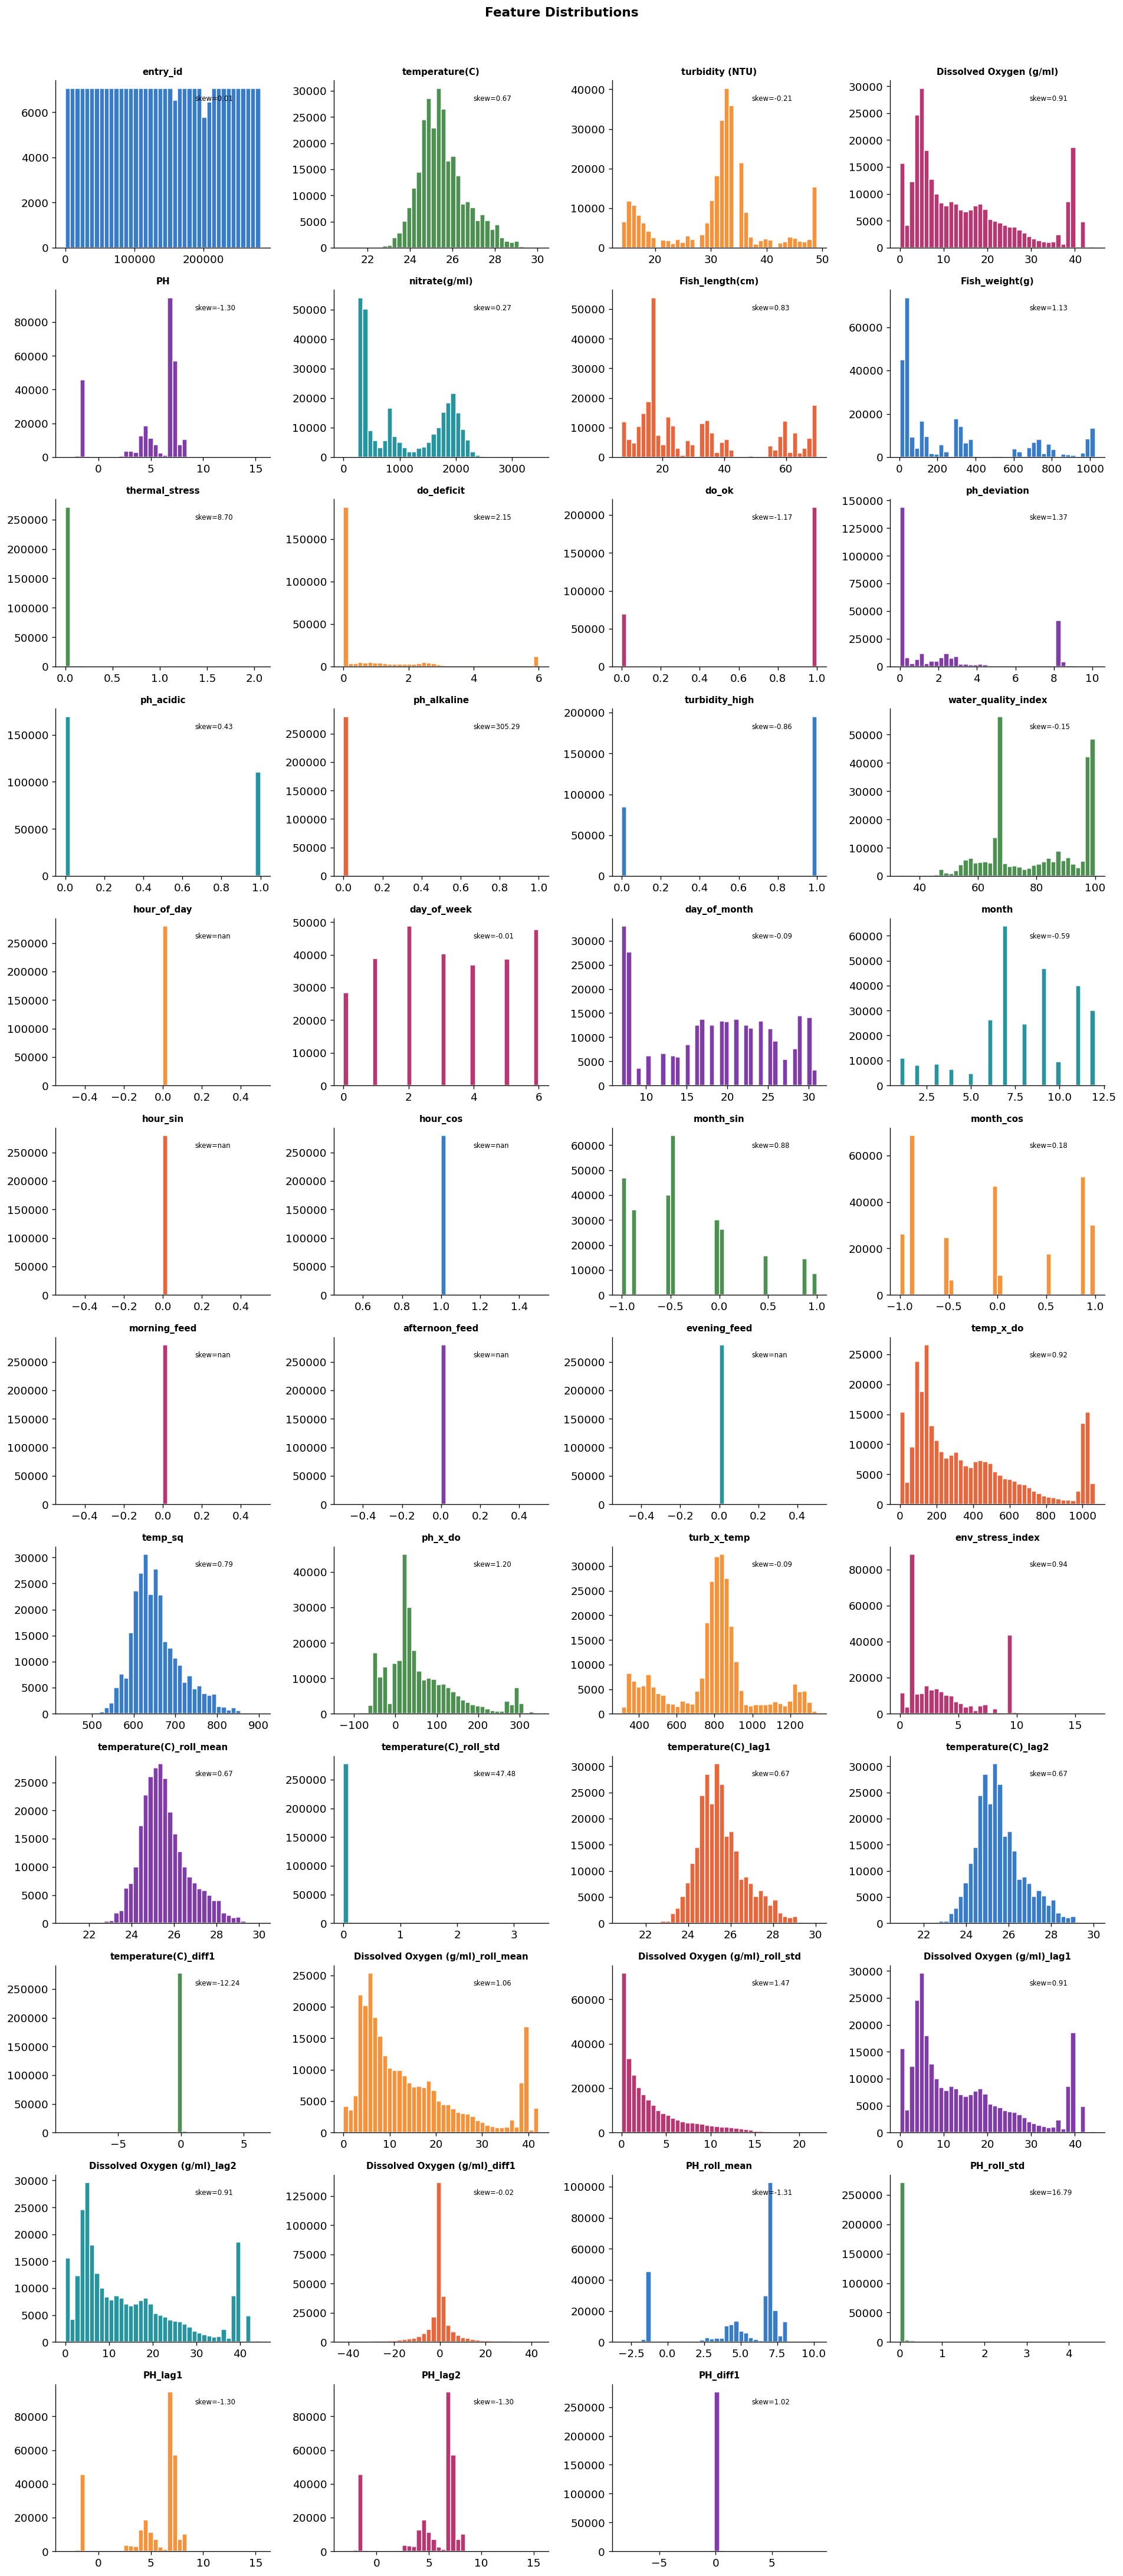

In [6]:
# ── Distributions ─────────────────────────────────────────────────────────────
if num_cols:
    n = len(num_cols); nc = 4; nr = (n+nc-1)//nc
    fig, axes = plt.subplots(nr, nc, figsize=(nc*4, nr*3))
    axes = axes.flatten()
    for i, col in enumerate(num_cols):
        axes[i].hist(df[col].dropna(), bins=40,
                     color=PALETTE[i%len(PALETTE)], edgecolor='white', alpha=0.85)
        axes[i].set_title(col, fontsize=9, fontweight='bold')
        axes[i].annotate(f'skew={skew(df[col].dropna()):.2f}',
                         xy=(0.65,0.88), xycoords='axes fraction', fontsize=7)
    for j in range(i+1, len(axes)): axes[j].set_visible(False)
    fig.suptitle('Feature Distributions', fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout(); plt.show()

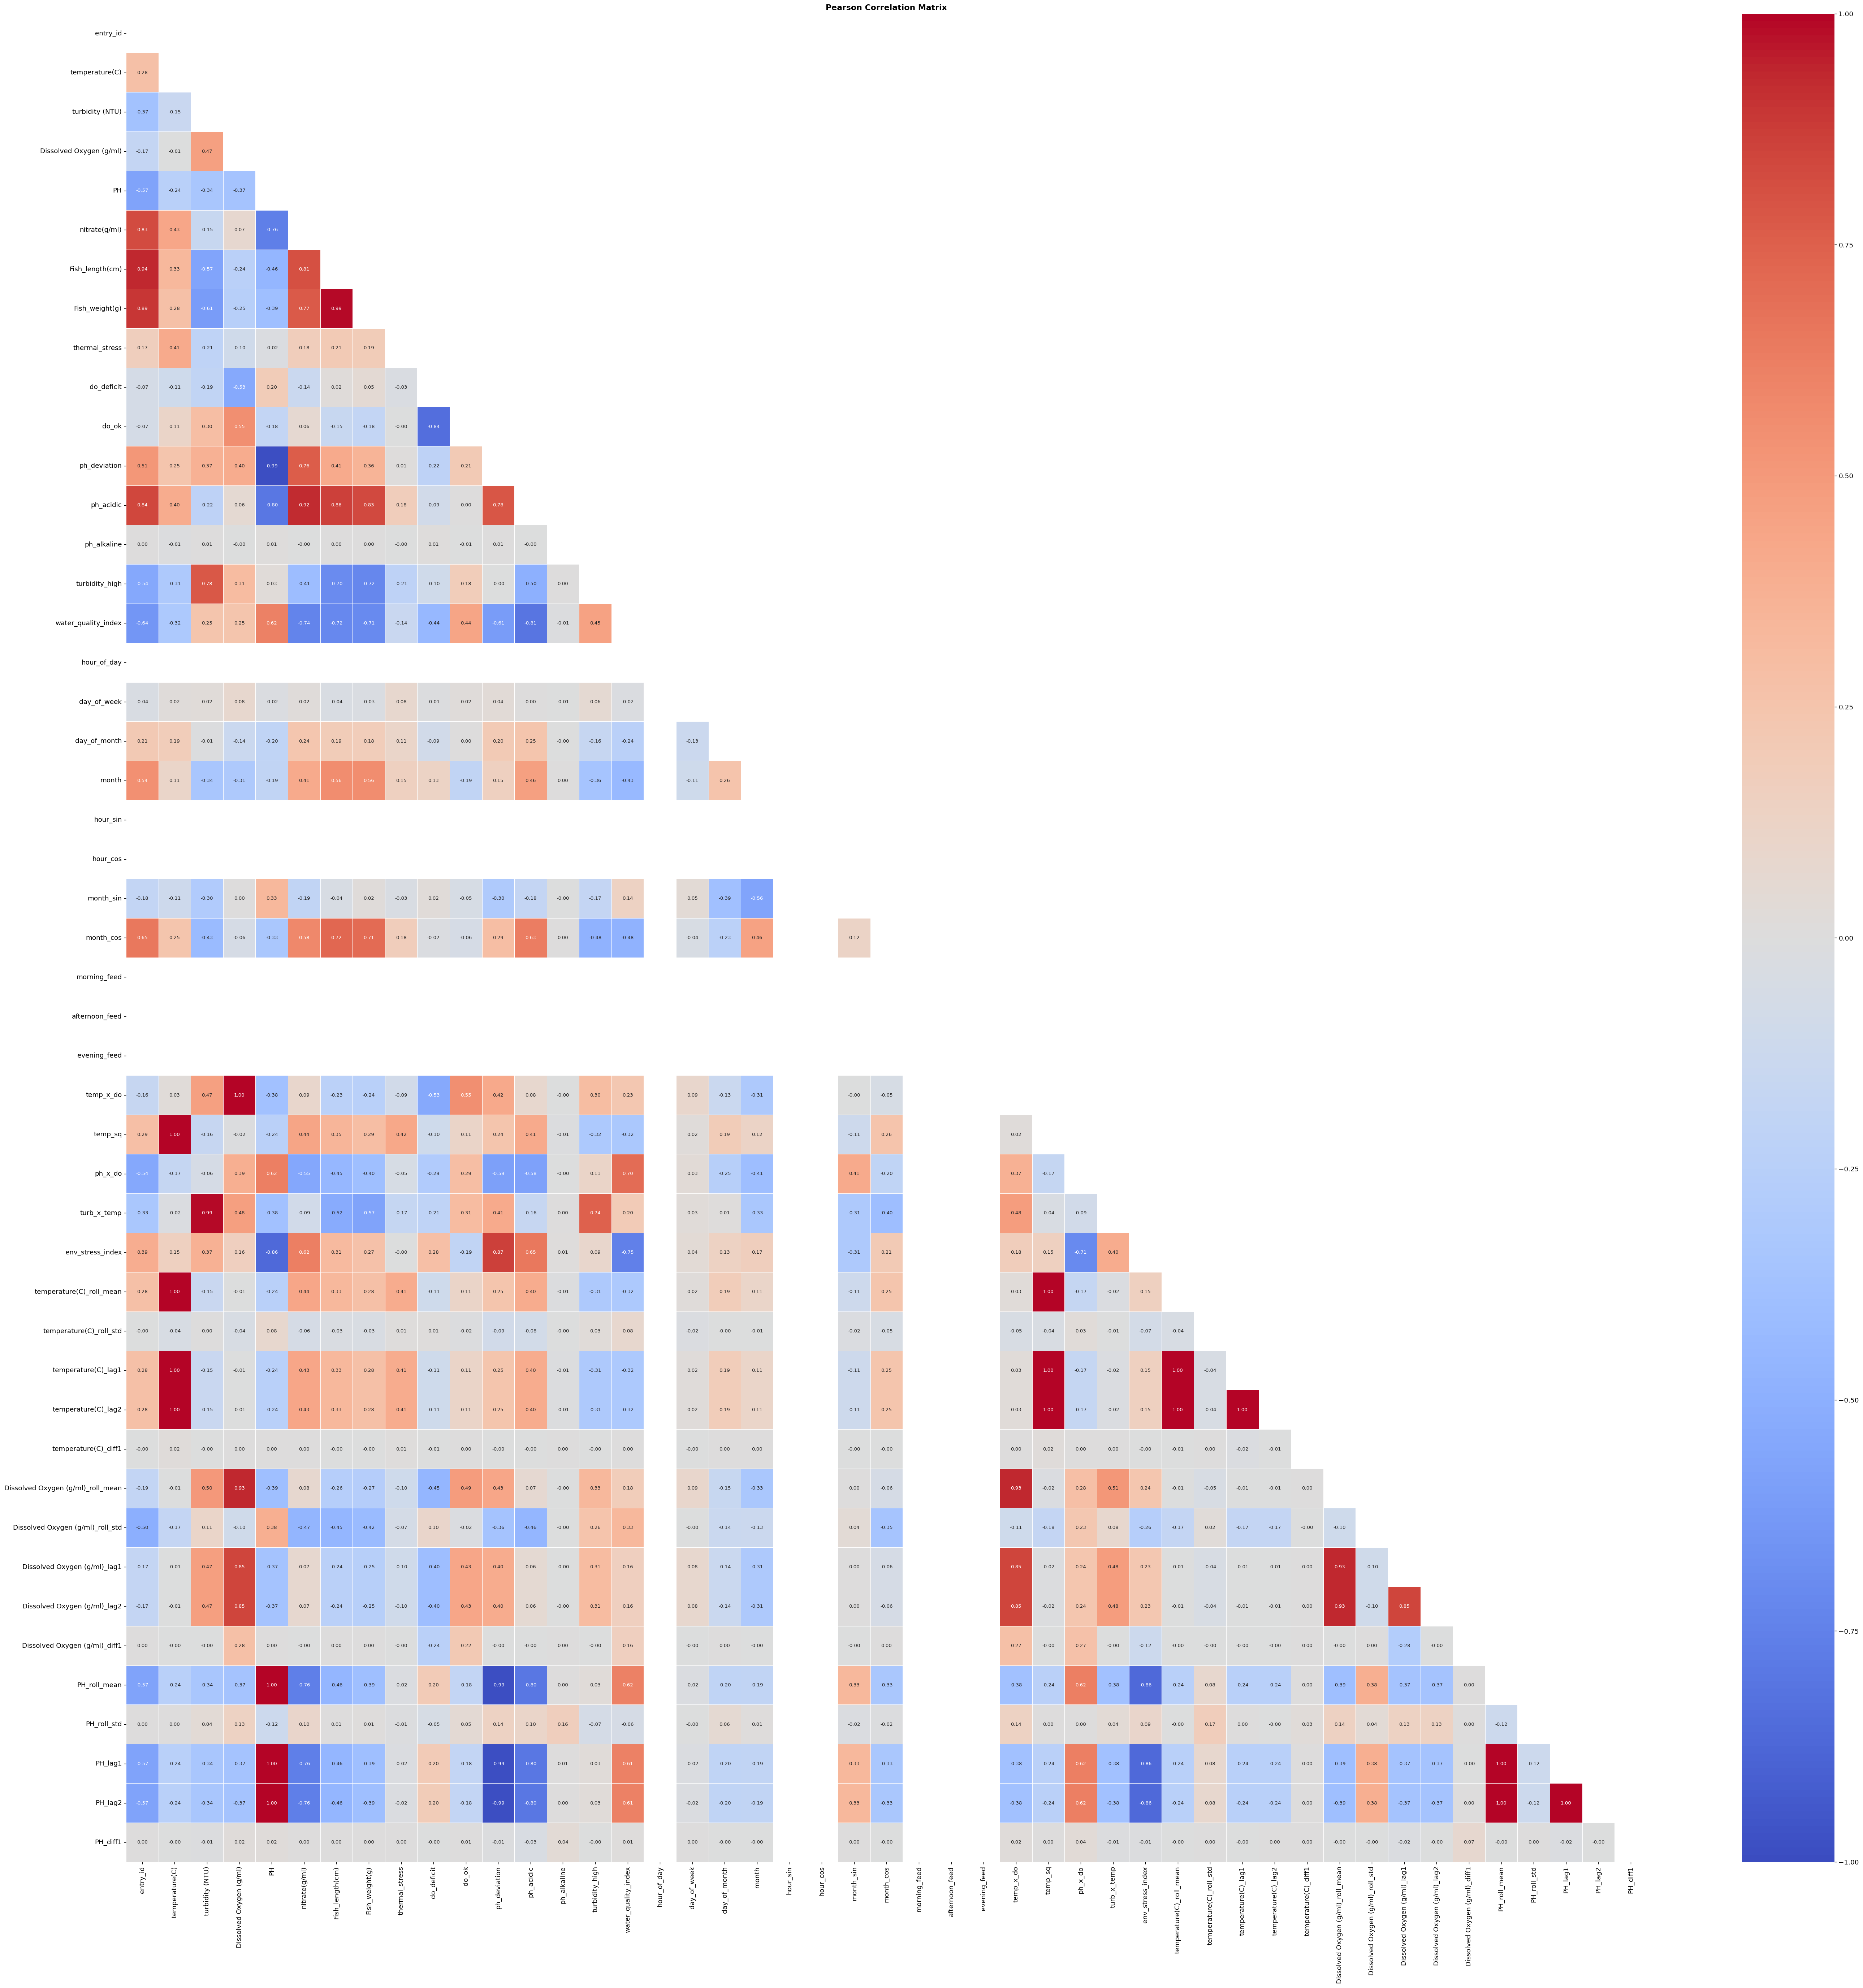

In [7]:
# ── Correlation heatmap ───────────────────────────────────────────────────────
if len(num_cols) >= 2:
    corr = df[num_cols].corr()
    mask = np.triu(np.ones_like(corr, dtype=bool))
    fig, ax = plt.subplots(figsize=(max(8,len(num_cols)), max(6,len(num_cols)-1)))
    sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
                center=0, vmin=-1, vmax=1, linewidths=0.5,
                ax=ax, annot_kws={'size':8})
    ax.set_title('Pearson Correlation Matrix', fontweight='bold')
    plt.tight_layout(); plt.show()

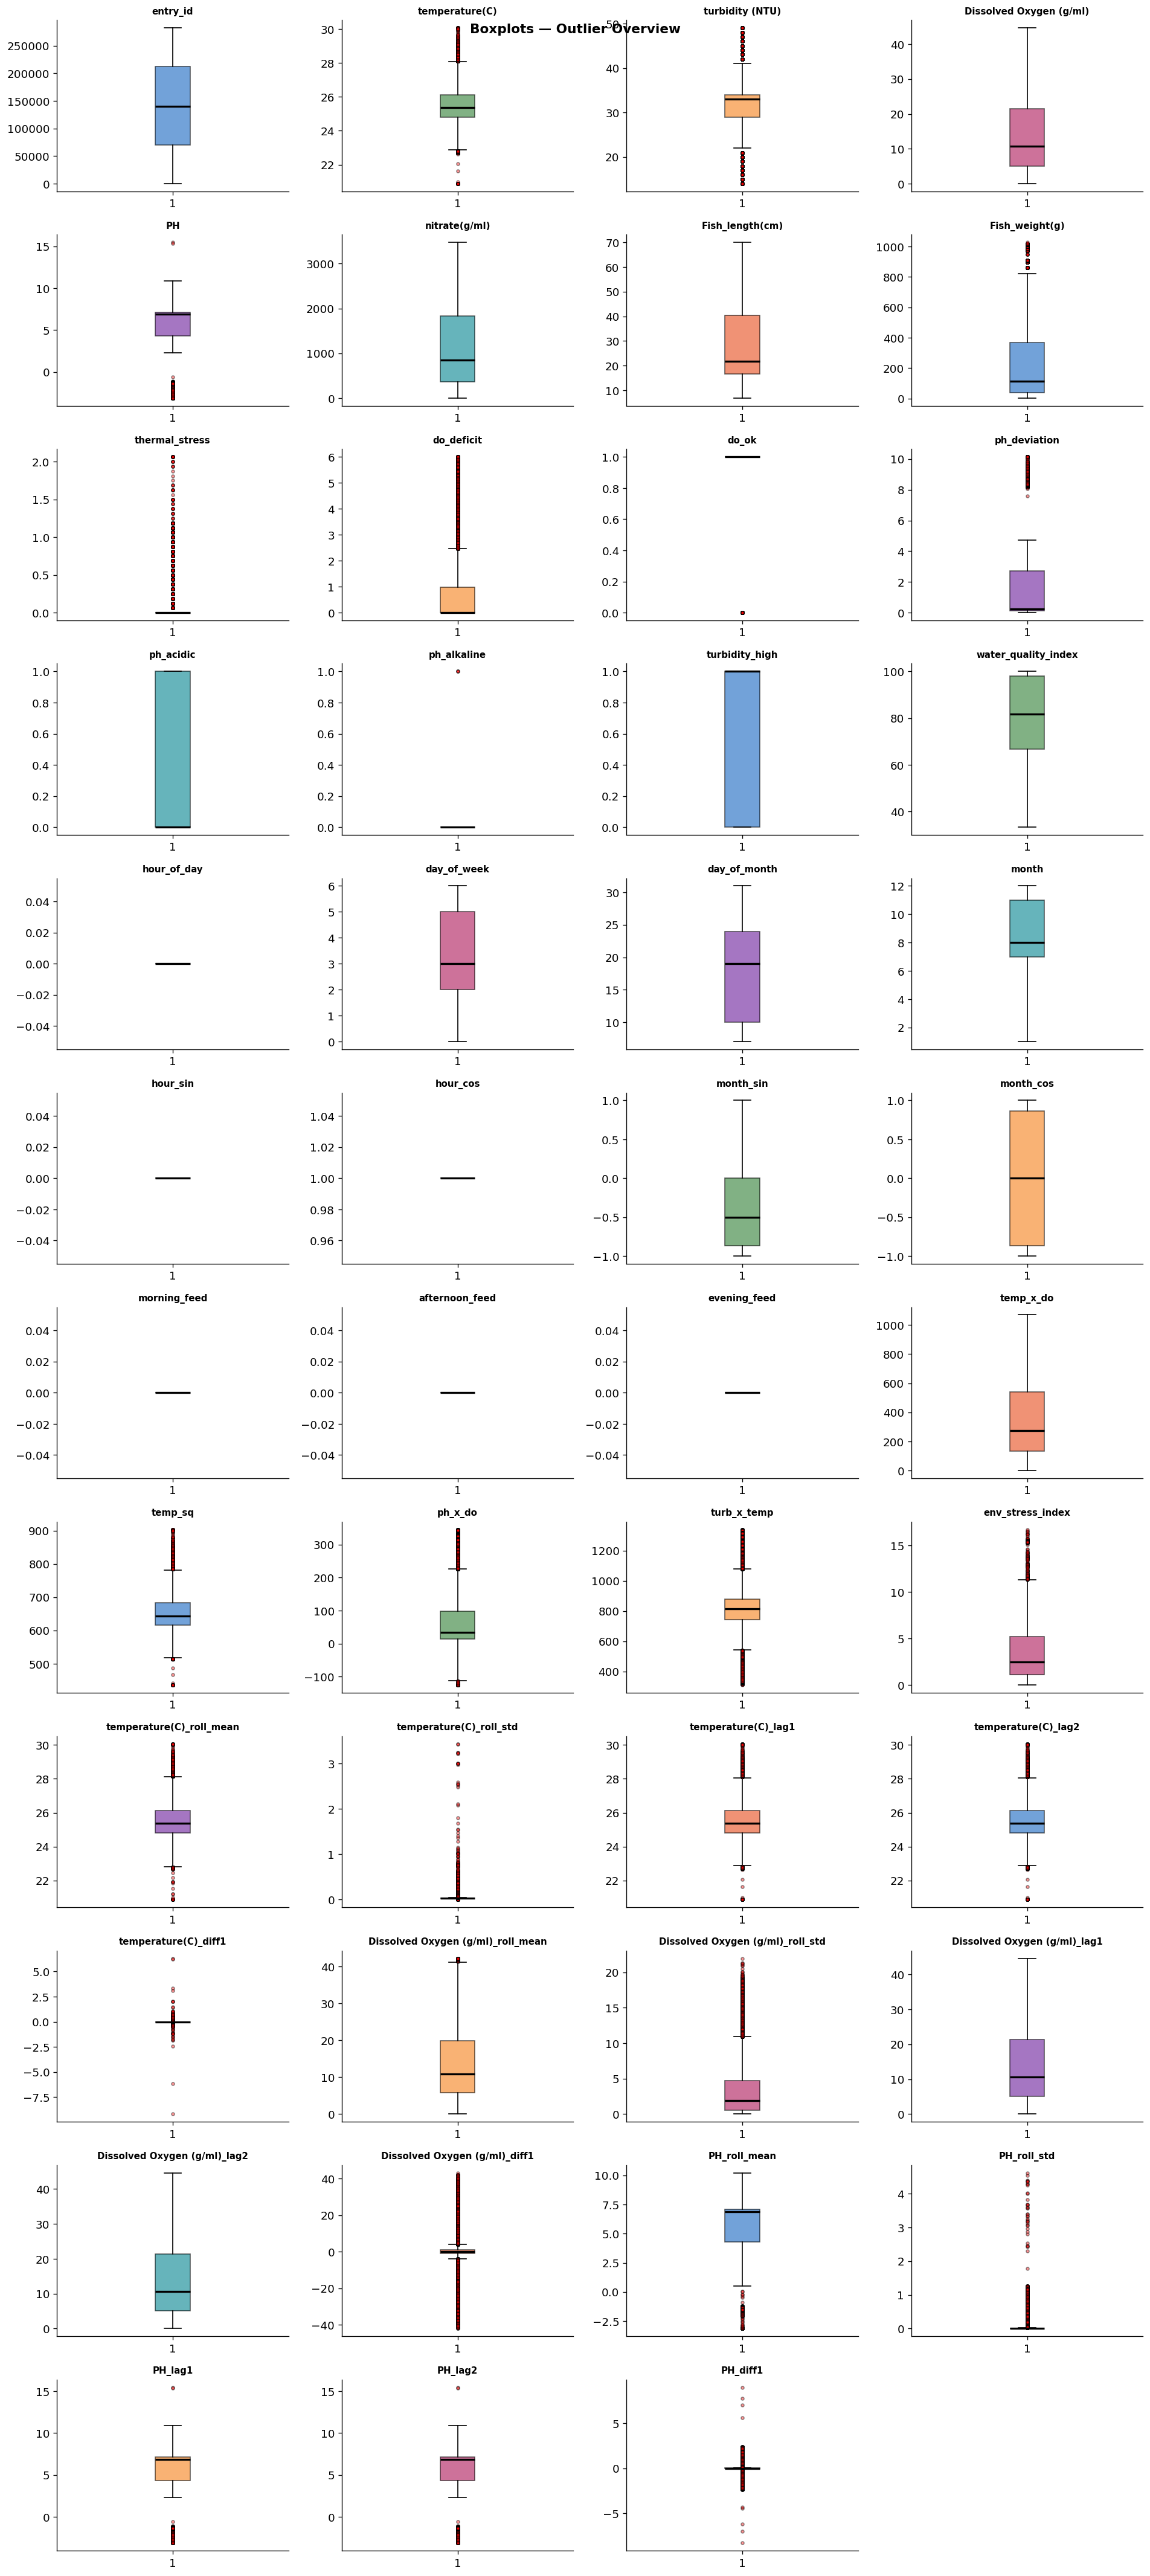

In [8]:
# ── Boxplots ──────────────────────────────────────────────────────────────────
if num_cols:
    n = len(num_cols); nc = 4; nr = (n+nc-1)//nc
    fig, axes = plt.subplots(nr, nc, figsize=(nc*4, nr*3))
    axes = axes.flatten()
    for i, col in enumerate(num_cols):
        axes[i].boxplot(df[col].dropna(), patch_artist=True,
                        boxprops=dict(facecolor=PALETTE[i%len(PALETTE)], alpha=0.6),
                        medianprops=dict(color='black', linewidth=2),
                        flierprops=dict(marker='o', markerfacecolor='red', markersize=3, alpha=0.4))
        axes[i].set_title(col, fontsize=9, fontweight='bold')
    for j in range(i+1, len(axes)): axes[j].set_visible(False)
    fig.suptitle('Boxplots — Outlier Overview', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

✅  Datetime: "Date"  [2021-01-07 00:00:00 → 2021-12-30 00:00:00]


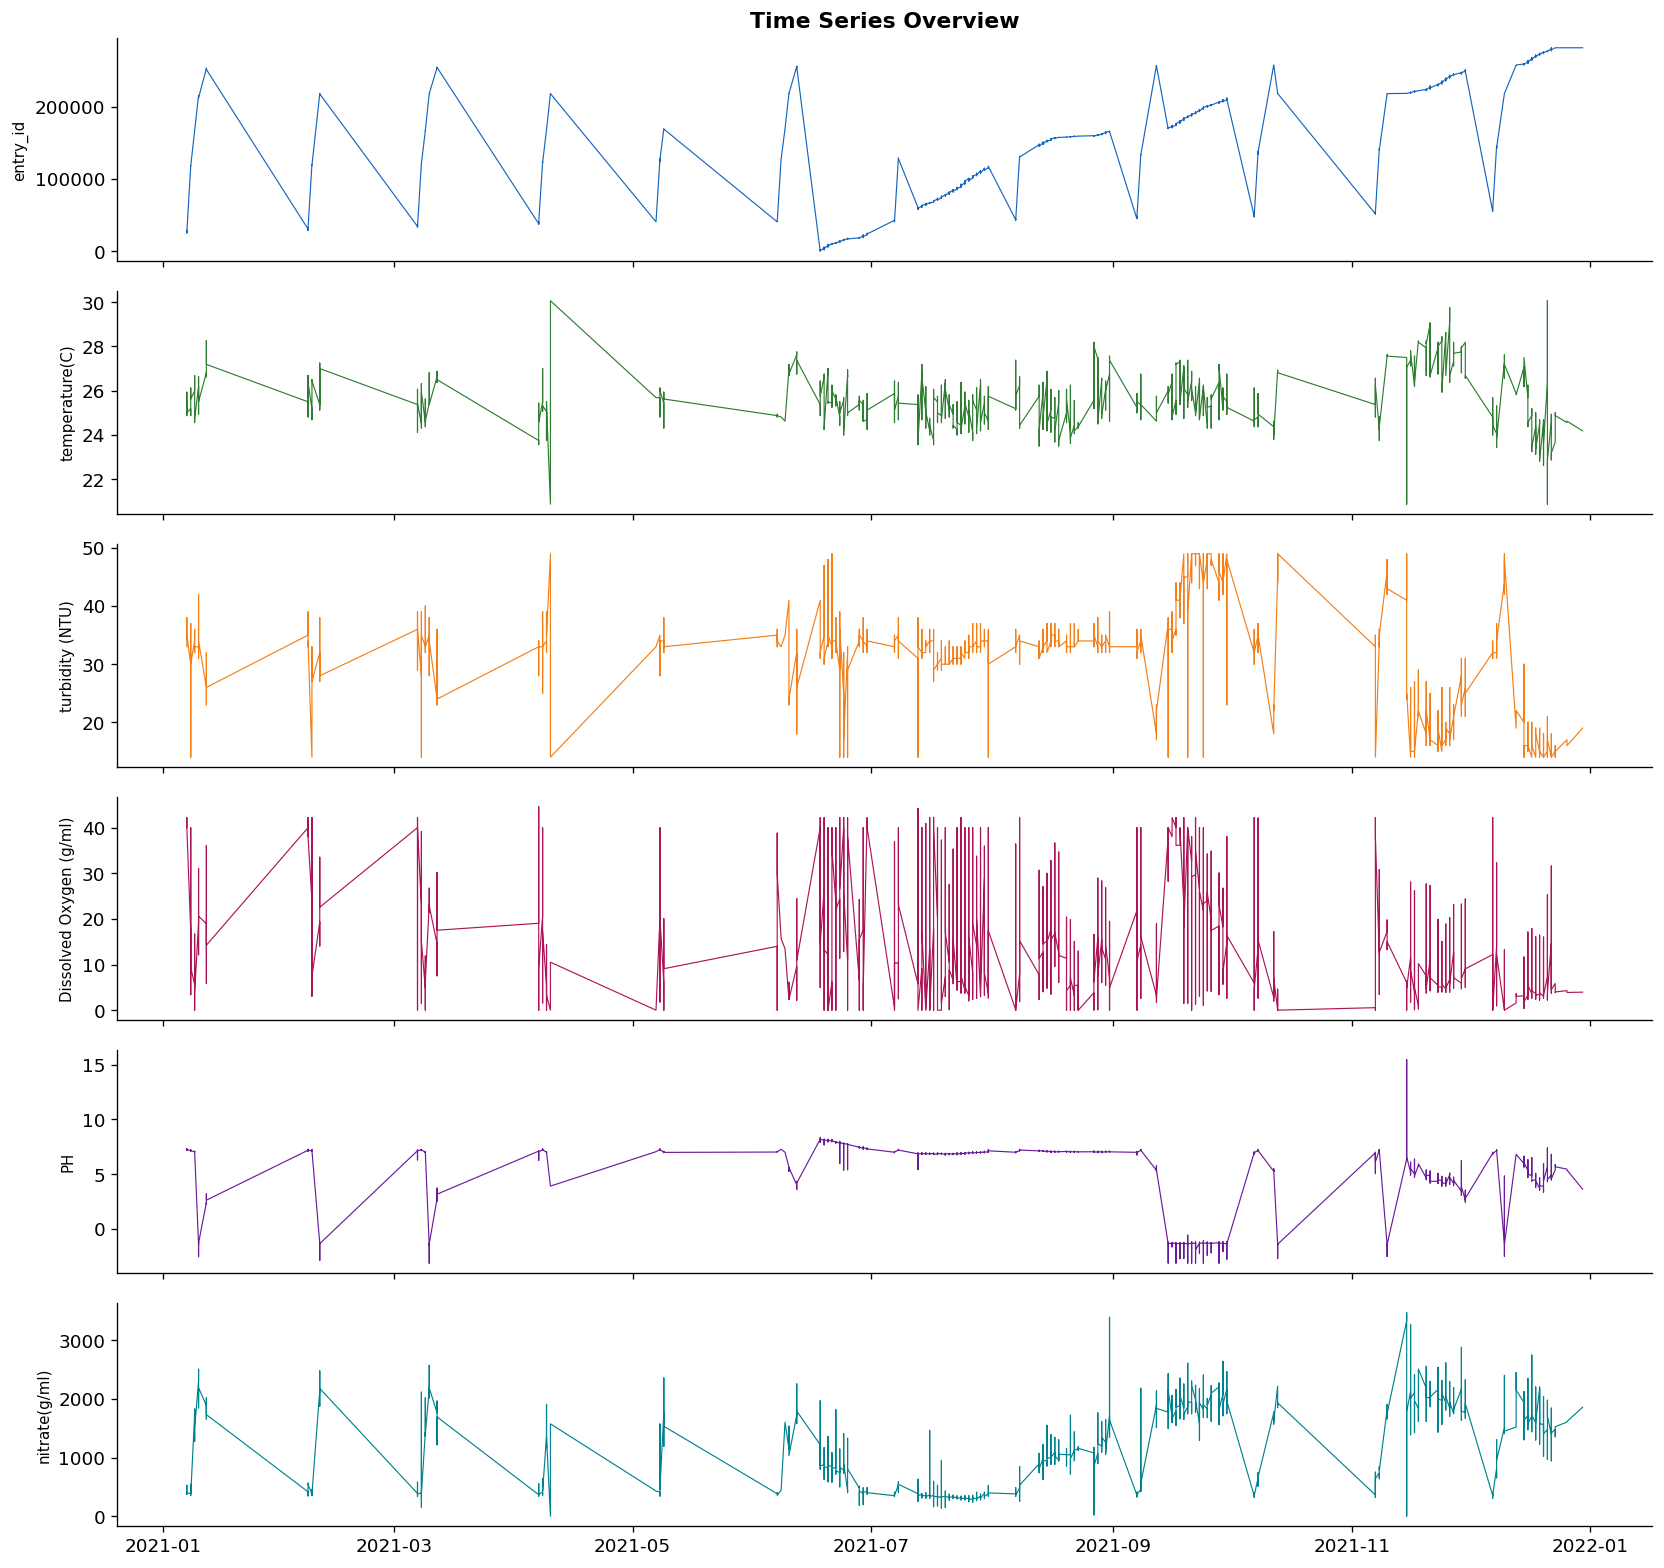

In [9]:
# ── Temporal plot (if datetime column found) ──────────────────────────────────
datetime_col = None
for col in df.columns:
    if any(k in col.lower() for k in TIME_KW):
        try:
            parsed = pd.to_datetime(df[col], infer_datetime_format=True, errors='coerce')
            if parsed.notna().mean() > 0.5:
                df[col] = parsed
                datetime_col = col
                print(f'✅  Datetime: "{col}"  [{parsed.min()} → {parsed.max()}]')
                break
        except: pass

if datetime_col:
    df_ts  = df.set_index(datetime_col).sort_index()
    pcols  = num_cols[:6]
    fig, axes = plt.subplots(len(pcols), 1, figsize=(14, len(pcols)*2.2), sharex=True)
    if len(pcols)==1: axes=[axes]
    for i, col in enumerate(pcols):
        axes[i].plot(df_ts[col].dropna(), color=PALETTE[i%len(PALETTE)], linewidth=0.7)
        axes[i].set_ylabel(col, fontsize=9)
    axes[0].set_title('Time Series Overview', fontweight='bold')
    plt.tight_layout(); plt.show()
else:
    print('ℹ️  No datetime column detected.')

---
## 5. 🧹 Data Cleaning

In [10]:
# ── Duplicates ────────────────────────────────────────────────────────────────
before = len(df)
df = df.drop_duplicates()
print(f'Duplicates removed: {before-len(df):,}')

# ── Drop >60% missing columns ─────────────────────────────────────────────────
high_null = df.columns[df.isna().mean() > 0.60].tolist()
if high_null:
    print(f'Dropping {len(high_null)} high-null columns: {high_null}')
    df.drop(columns=high_null, inplace=True)

# ── Fix numeric columns stored as strings ─────────────────────────────────────
num_cols = df.select_dtypes(include='number').columns.tolist()
cat_cols = df.select_dtypes(include='object').columns.tolist()
for col in cat_cols[:]:
    conv = pd.to_numeric(df[col].astype(str).str.replace(',','.'), errors='coerce')
    if conv.notna().mean() > 0.85:
        df[col] = conv
        cat_cols.remove(col); num_cols.append(col)
        print(f'  Converted to numeric: {col}')

# ── Outlier clipping  (3×IQR soft fence) ─────────────────────────────────────
for col in num_cols:
    Q1, Q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    IQR = Q3 - Q1
    df[col] = df[col].clip(Q1 - 3*IQR, Q3 + 3*IQR)

# ── Imputation ────────────────────────────────────────────────────────────────
miss = df[num_cols].isna().mean()
low  = miss[(miss>0) & (miss<0.05)].index.tolist()
high = miss[(miss>=0.05) & (miss<=0.60)].index.tolist()
if low:  df[low]  = SimpleImputer(strategy='median').fit_transform(df[low])
if high: df[high] = KNNImputer(n_neighbors=5).fit_transform(df[high])
for col in cat_cols:
    if df[col].isna().sum(): df[col].fillna(df[col].mode()[0], inplace=True)

print(f'\n✅  Clean dataset: {df.shape[0]:,} rows × {df.shape[1]} cols  |  nulls={df.isna().sum().sum()}')

Duplicates removed: 0

✅  Clean dataset: 279,612 rows × 51 cols  |  nulls=0


---
## 6. ⚙️ Feature Engineering

In [11]:
def find_col(keywords):
    for col in df.columns:
        if any(k in col.lower() for k in keywords): return col
    return None

C_TEMP  = find_col(['temp','temperature'])
C_DO    = find_col(['dissolved','oxygen',' do','o2'])
C_PH    = find_col(['ph'])
C_TURB  = find_col(['turb','turbid'])
C_SAL   = find_col(['salinity','salt','tds','conductivity'])
C_FEED  = find_col(['feed','food','amount','quantity'])
C_WT    = find_col(['weight','biomass'])
C_AMMO  = find_col(['ammonia','nh3','nh4'])

print('Column mapping:')
for n,v in [('Temperature',C_TEMP),('DO',C_DO),('pH',C_PH),('Turbidity',C_TURB),
             ('Salinity',C_SAL),('Feed',C_FEED),('Weight',C_WT),('Ammonia',C_AMMO)]:
    print(f'  {n:<14}: {v or "NOT FOUND"}')

Column mapping:
  Temperature   : temperature(C)
  DO            : Dissolved Oxygen (g/ml)
  pH            : PH
  Turbidity     : turbidity (NTU)
  Salinity      : NOT FOUND
  Feed          : morning_feed
  Weight        : Fish_weight(g)
  Ammonia       : NOT FOUND


In [12]:
# ── Environmental stress features ─────────────────────────────────────────────
if C_TEMP:
    df['thermal_stress'] = np.where(df[C_TEMP]<20, 20-df[C_TEMP],
                           np.where(df[C_TEMP]>28, df[C_TEMP]-28, 0))
if C_DO:
    df['do_deficit']  = (6.0 - df[C_DO]).clip(lower=0)
    df['do_ok']       = (df[C_DO] >= 5.0).astype(int)
if C_PH:
    df['ph_deviation']= (df[C_PH] - 7.0).abs()
    df['ph_acidic']   = (df[C_PH] < 6.5).astype(int)
    df['ph_alkaline'] = (df[C_PH] > 8.5).astype(int)
if C_TURB:
    df['turbidity_high'] = (df[C_TURB] > 30).astype(int)
if C_AMMO:
    df['ammonia_toxic'] = (df[C_AMMO] > 0.02).astype(int)

# ── Water Quality Index (0–100) ───────────────────────────────────────────────
wqi_parts = {}
if C_TEMP: wqi_parts['w_temp'] = 100*(1-(df['thermal_stress']/10).clip(0,1))
if C_DO:   wqi_parts['w_do']   = df[C_DO].clip(0,8)/8*100
if C_PH:   wqi_parts['w_ph']   = 100-df['ph_deviation'].clip(0,3)/3*100
if wqi_parts:
    df['water_quality_index'] = pd.DataFrame(wqi_parts).mean(axis=1).round(2)
    df['wqi_category'] = pd.cut(df['water_quality_index'],
                                 bins=[0,40,60,80,100],
                                 labels=['Poor','Fair','Good','Excellent'])

# ── Feeding efficiency ────────────────────────────────────────────────────────
if C_FEED and C_WT:
    df['fcr_proxy']    = df[C_FEED] / (df[C_WT] + 1e-9)
    df['feed_per_kg']  = df[C_FEED] / df[C_WT].clip(lower=0.01)

# ── Interaction features ──────────────────────────────────────────────────────
if C_TEMP and C_DO:   df['temp_x_do']   = df[C_TEMP] * df[C_DO]
if C_PH   and C_DO:   df['ph_x_do']     = df[C_PH]   * df[C_DO]
if C_TURB and C_TEMP: df['turb_x_temp'] = df[C_TURB]  * df[C_TEMP]
if C_TEMP:            df['temp_sq']     = df[C_TEMP]  ** 2

# ── Overall stress index ──────────────────────────────────────────────────────
stress = [c for c in ['thermal_stress','do_deficit','ph_deviation',
                       'turbidity_high','ammonia_toxic'] if c in df.columns]
if stress: df['env_stress_index'] = df[stress].sum(axis=1)

# ── Temporal features ─────────────────────────────────────────────────────────
if datetime_col and datetime_col in df.columns:
    dt = pd.to_datetime(df[datetime_col], errors='coerce')
    df['hour_of_day']  = dt.dt.hour
    df['day_of_week']  = dt.dt.dayofweek
    df['month']        = dt.dt.month
    df['hour_sin']     = np.sin(2*np.pi*df['hour_of_day']/24)
    df['hour_cos']     = np.cos(2*np.pi*df['hour_of_day']/24)
    df['month_sin']    = np.sin(2*np.pi*df['month']/12)
    df['month_cos']    = np.cos(2*np.pi*df['month']/12)
    df['morning_feed'] = df['hour_of_day'].between(6,9).astype(int)
    df['evening_feed'] = df['hour_of_day'].between(17,20).astype(int)

# ── Rolling & lag features ────────────────────────────────────────────────────
roll_src = [c for c in [C_TEMP, C_DO, C_PH, C_FEED] if c]
for col in roll_src:
    df[f'{col}_roll6_mean'] = df[col].rolling(6, min_periods=2).mean()
    df[f'{col}_roll6_std']  = df[col].rolling(6, min_periods=2).std()
    df[f'{col}_lag1']       = df[col].shift(1)
    df[f'{col}_diff1']      = df[col].diff(1)

roll_cols = [c for c in df.columns if any(s in c for s in ['_roll','_lag','_diff'])]
df[roll_cols] = df[roll_cols].fillna(method='bfill').fillna(0)

new_feats = [c for c in df.columns if c not in dfs[MAIN_KEY].columns]
print(f'✅  {len(new_feats)} new features engineered.')
print(f'📊  Dataset shape: {df.shape}')

✅  12 new features engineered.
📊  Dataset shape: (279612, 63)


---
## 7. 🎯 Feature Selection

In [13]:
# ── Determine target ──────────────────────────────────────────────────────────
TARGET = None
for c in tgt_cands + beh_cols:
    if c in df.columns: TARGET = c; break
if TARGET is None:
    TARGET = df.select_dtypes(include='number').columns[-1]
print(f'🎯  Target: "{TARGET}"  ← override if wrong')

# ── Build feature matrix ──────────────────────────────────────────────────────
EXCLUDE = set(([TARGET] if TARGET else []) + time_cols +
              [c for c,t in col_tags.items() if t=='metadata'] +
              ['wqi_category','season'])

feat_cols = [c for c in df.select_dtypes(include='number').columns
             if c not in EXCLUDE]
X = df[feat_cols].copy()
y = df[TARGET].copy()

valid = X.notna().all(axis=1) & y.notna()
X, y  = X[valid], y[valid]
print(f'X: {X.shape}  |  y: {y.shape}')

🎯  Target: "wqi_category"  ← override if wrong
X: (279612, 45)  |  y: (279612,)


Removing 15 low-variance features.
Removing 14 highly-correlated features.

🔧  Task: CLASSIFICATION  |  Features remaining: 16


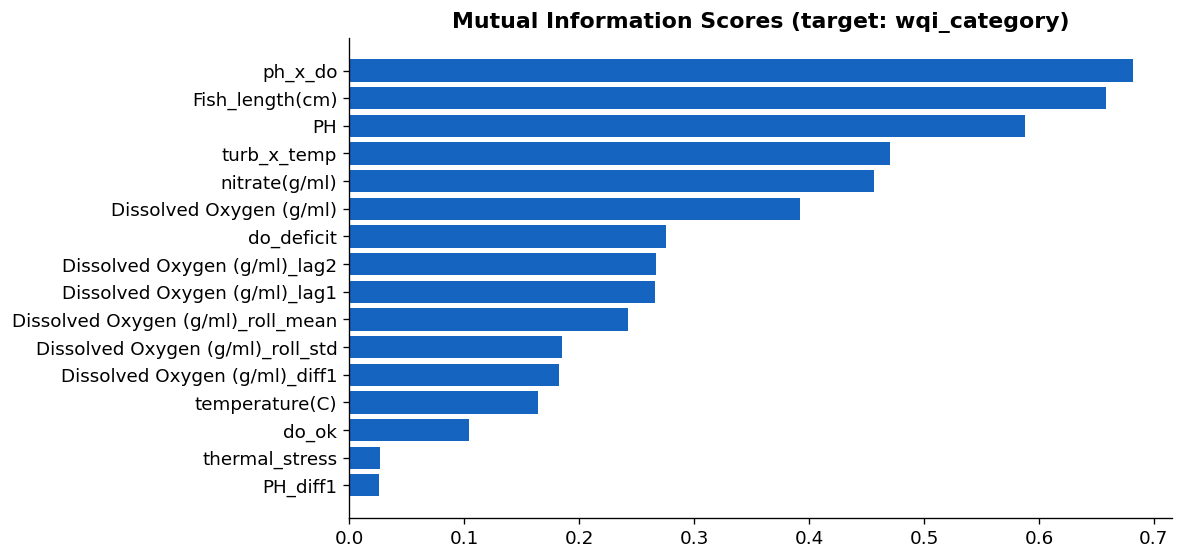


✅  Selected 16 features.


In [14]:
# ── 1. Variance threshold ─────────────────────────────────────────────────────
vt      = VarianceThreshold(threshold=0.01)
vt.fit(X)
low_var = X.columns[~vt.get_support()].tolist()
if low_var:
    print(f'Removing {len(low_var)} low-variance features.')
    X = X.loc[:, vt.get_support()]          # ← boolean mask (no KeyError)
    feat_cols = X.columns.tolist()

# ── 2. High correlation removal (|r|>0.95) ────────────────────────────────────
corr_m = X.corr().abs()
upper  = corr_m.where(np.triu(np.ones_like(corr_m, dtype=bool), k=1))
drop_c = [c for c in upper.columns if any(upper[c] > 0.95)]
if drop_c:
    print(f'Removing {len(drop_c)} highly-correlated features.')
    X.drop(columns=drop_c, inplace=True)
    feat_cols = X.columns.tolist()

# ── 3. Mutual information ranking ─────────────────────────────────────────────
IS_REGRESSION = (y.dtype in ['float64','float32']) or (y.nunique() > 15)
TASK = 'regression' if IS_REGRESSION else 'classification'
print(f'\n🔧  Task: {TASK.upper()}  |  Features remaining: {len(feat_cols)}')

mi_fn  = mutual_info_regression if IS_REGRESSION else mutual_info_classif
mi_sc  = mi_fn(X.fillna(0), y, random_state=42)
mi_df  = pd.DataFrame({'feature': feat_cols, 'MI': mi_sc}).sort_values('MI', ascending=False)

fig, ax = plt.subplots(figsize=(10, max(4, len(feat_cols)*0.3)))
ax.barh(mi_df['feature'][::-1], mi_df['MI'][::-1], color='#1565C0')
ax.set_title(f'Mutual Information Scores (target: {TARGET})', fontweight='bold')
plt.tight_layout(); plt.show()

SELECTED = mi_df[mi_df['MI'] > 0]['feature'].tolist()
if len(SELECTED) < 5: SELECTED = mi_df.head(max(5, len(mi_df)//2))['feature'].tolist()
print(f'\n✅  Selected {len(SELECTED)} features.')

---
## 8. 🔧 Preprocessing & Splits

In [15]:
X_final = X[SELECTED]

# 70 / 15 / 15 split
X_tv, X_test, y_tv, y_test = train_test_split(X_final, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.176, random_state=42)

# RobustScaler (best for sensor data with residual outliers)
scaler = RobustScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

# Encode categorical target if needed
le = None
if y_train.dtype == 'object':
    le = LabelEncoder()
    y_train = le.fit_transform(y_train)
    y_val   = le.transform(y_val)
    y_test  = le.transform(y_test)
    print(f'✅  LabelEncoded classes: {le.classes_}')

print(f'Train  : {X_train_sc.shape}  |  Val: {X_val_sc.shape}  |  Test: {X_test_sc.shape}')

# Convert splits back to DataFrames for sklearn ────────────────────────────────
X_tr = pd.DataFrame(X_train_sc, columns=SELECTED)
X_va = pd.DataFrame(X_val_sc,   columns=SELECTED)
X_te = pd.DataFrame(X_test_sc,  columns=SELECTED)

Train  : (195840, 16)  |  Val: (41830, 16)  |  Test: (41942, 16)


---
## 9. 🤖 Model Training

In [16]:
# ── Evaluation helper ─────────────────────────────────────────────────────────
RESULTS = []
trained_models = {}

def evaluate(model, X, y_true):
    p = model.predict(X)
    if IS_REGRESSION:
        return {'MAE':  mean_absolute_error(y_true, p),
                'RMSE': mean_squared_error(y_true, p, squared=False),
                'R2':   r2_score(y_true, p)}
    else:
        acc = accuracy_score(y_true, p)
        f1  = f1_score(y_true, p, average='weighted', zero_division=0)
        try:
            pb = model.predict_proba(X)
            auc = roc_auc_score(y_true, pb, multi_class='ovr', average='weighted') \
                  if pb.shape[1]>2 else roc_auc_score(y_true, pb[:,1])
        except: auc = float('nan')
        return {'Acc': acc, 'F1': f1, 'AUC': auc}

def register(name, model, fit_time):
    vm = evaluate(model, X_va, y_val)
    tm = evaluate(model, X_tr, y_train)
    row = {'model': name, 'fit_time': round(fit_time,2)}
    row.update({f'val_{k}':v for k,v in vm.items()})
    row.update({f'trn_{k}':v for k,v in tm.items()})
    RESULTS.append(row)
    trained_models[name] = model
    if IS_REGRESSION:
        print(f'  {name:<38}  MAE={vm["MAE"]:.4f}  RMSE={vm["RMSE"]:.4f}  R²={vm["R2"]:.4f}  ({fit_time:.1f}s)')
    else:
        print(f'  {name:<38}  Acc={vm["Acc"]:.4f}  F1={vm["F1"]:.4f}  AUC={vm["AUC"]:.4f}  ({fit_time:.1f}s)')

In [17]:
print('── BASELINES ────────────────────────────────────────────────────')
if IS_REGRESSION:
    baselines = [
        ('Linear Regression', LinearRegression()),
        ('Ridge',             Ridge(alpha=1.0)),
        ('Lasso',             Lasso(alpha=0.01, max_iter=5000)),
        ('Decision Tree',     DecisionTreeRegressor(max_depth=6, random_state=42)),
        ('KNN (k=7)',          KNeighborsRegressor(n_neighbors=7)),
    ]
else:
    baselines = [
        ('Logistic Regression', LogisticRegression(max_iter=1000, random_state=42)),
        ('Decision Tree',       DecisionTreeClassifier(max_depth=6, random_state=42)),
        ('KNN (k=7)',            KNeighborsClassifier(n_neighbors=7)),
    ]

for name, m in baselines:
    t0 = time.time(); m.fit(X_tr, y_train); register(name, m, time.time()-t0)

── BASELINES ────────────────────────────────────────────────────
  Logistic Regression                     Acc=0.9523  F1=0.9523  AUC=0.9931  (37.5s)
  Decision Tree                           Acc=0.9864  F1=0.9858  AUC=0.9985  (1.6s)
  KNN (k=7)                               Acc=0.9730  F1=0.9730  AUC=0.9961  (0.2s)


In [18]:
print('── ENSEMBLES ────────────────────────────────────────────────────')
if IS_REGRESSION:
    ensembles = [
        ('Random Forest',     RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1)),
        ('Extra Trees',       ExtraTreesRegressor(n_estimators=300,   random_state=42, n_jobs=-1)),
        ('Gradient Boosting', GradientBoostingRegressor(n_estimators=300, learning_rate=0.05,
                                                         max_depth=5, random_state=42)),
    ]
else:
    ensembles = [
        ('Random Forest',     RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
        ('Extra Trees',       ExtraTreesClassifier(n_estimators=300,   random_state=42, n_jobs=-1)),
        ('Gradient Boosting', GradientBoostingClassifier(n_estimators=300, learning_rate=0.05,
                                                          max_depth=5, random_state=42)),
    ]

for name, m in ensembles:
    t0 = time.time(); m.fit(X_tr, y_train); register(name, m, time.time()-t0)

── ENSEMBLES ────────────────────────────────────────────────────
  Random Forest                           Acc=0.9982  F1=0.9982  AUC=1.0000  (43.0s)
  Extra Trees                             Acc=0.9973  F1=0.9973  AUC=1.0000  (10.5s)
  Gradient Boosting                       Acc=0.9983  F1=0.9983  AUC=1.0000  (1393.0s)


In [19]:
print('── XGBOOST + LIGHTGBM ───────────────────────────────────────────')

# ── Permanently encode y to numeric if needed (fixes ALL downstream models) ───
from sklearn.preprocessing import LabelEncoder
import numpy as np

if not np.issubdtype(np.array(y_train).dtype, np.number):
    _le = LabelEncoder()
    # Fit on all unique values across all splits to avoid unseen label errors
    _le.fit(np.concatenate([
        np.array(y_train).ravel(),
        np.array(y_val).ravel(),
        np.array(y_test).ravel()
    ]))
    y_train = _le.transform(np.array(y_train).ravel())
    y_val   = _le.transform(np.array(y_val).ravel())
    y_test  = _le.transform(np.array(y_test).ravel())
    print(f'  ✅  Globally encoded classes: {list(_le.classes_)}')
    print(f'      y_train dtype now: {y_train.dtype}')
else:
    _le = None
    print('  ✅  Target already numeric — no encoding needed.')

# ── XGBoost ────────────────────────────────────────────────────────────────────
if XGB_OK:
    params = dict(
        n_estimators          = 500,
        learning_rate         = 0.05,
        max_depth             = 6,
        subsample             = 0.8,
        colsample_bytree      = 0.8,
        reg_alpha             = 0.1,
        early_stopping_rounds = 30,
        random_state          = 42,
        tree_method           = 'hist',
        device                = 'cpu',
        verbosity             = 0,
    )
    if IS_REGRESSION:
        xgb_m = xgb.XGBRegressor(**params, eval_metric='rmse')
    else:
        xgb_m = xgb.XGBClassifier(**params, eval_metric='mlogloss')

    t0 = time.time()
    xgb_m.fit(X_tr, y_train, eval_set=[(X_va, y_val)], verbose=False)
    register('XGBoost', xgb_m, time.time() - t0)
else:
    print('  XGBoost not available — skipped.')

# ── LightGBM ───────────────────────────────────────────────────────────────────
if LGB_OK:
    lp = dict(
        n_estimators     = 500,
        learning_rate    = 0.05,
        num_leaves       = 63,
        subsample        = 0.8,
        colsample_bytree = 0.8,
        reg_alpha        = 0.1,
        random_state     = 42,
        n_jobs           = -1,
        verbose          = -1,
    )
    lgb_m = lgb.LGBMRegressor(**lp) if IS_REGRESSION else lgb.LGBMClassifier(**lp)

    t0 = time.time()
    lgb_m.fit(
        X_tr, y_train,
        eval_set  = [(X_va, y_val)],
        callbacks = [lgb.early_stopping(30, verbose=False), lgb.log_evaluation(-1)],
    )
    register('LightGBM', lgb_m, time.time() - t0)
else:
    print('  LightGBM not available — skipped.')

── XGBOOST + LIGHTGBM ───────────────────────────────────────────
  ✅  Globally encoded classes: ['Excellent', 'Fair', 'Good', 'Poor']
      y_train dtype now: int64
  XGBoost                                 Acc=0.9984  F1=0.9984  AUC=1.0000  (18.5s)
  LightGBM                                Acc=0.9982  F1=0.9982  AUC=1.0000  (7.6s)


── MLP NEURAL NETWORK ───────────────────────────────────────────
  ⚠️  CUDA unavailable (AcceleratorError) — falling back to CPU
  Early stop @ epoch 155


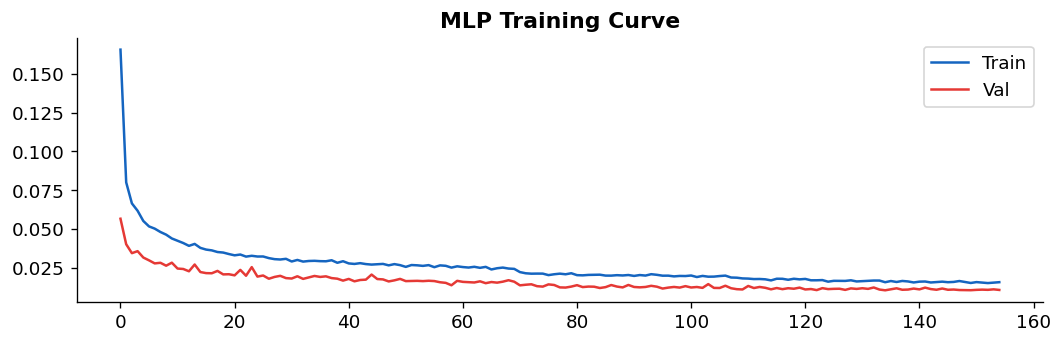

  MLP (Neural Network)                    Acc=0.9965  F1=0.9965  AUC=1.0000  (864.6s)


In [20]:
print('── MLP NEURAL NETWORK ───────────────────────────────────────────')
if TORCH_OK:
    # ── Force CPU if CUDA kernel is incompatible with the driver ──────────────
    try:
        _test = torch.tensor([1.0]).cuda()
        _ = _test * 2          # triggers the actual kernel call
        DEVICE = torch.device('cuda')
        print('  Using CUDA')
    except Exception as _cuda_err:
        DEVICE = torch.device('cpu')
        print(f'  ⚠️  CUDA unavailable ({type(_cuda_err).__name__}) — falling back to CPU')

    def t32(arr):
        return torch.tensor(np.array(arr), dtype=torch.float32).to(DEVICE)

    Xtr_t = t32(X_tr.values)
    Xva_t = t32(X_va.values)

    if IS_REGRESSION:
        ytr_t = t32(y_train).unsqueeze(1)
        yva_t = t32(y_val).unsqueeze(1)
    else:
        ytr_t = torch.tensor(np.array(y_train), dtype=torch.long).to(DEVICE)
        yva_t = torch.tensor(np.array(y_val),   dtype=torch.long).to(DEVICE)

    loader = DataLoader(TensorDataset(Xtr_t, ytr_t), batch_size=256, shuffle=True)

    class MLP(nn.Module):
        def __init__(self, inp, out):
            super().__init__()
            self.net = nn.Sequential(
                nn.Linear(inp, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
                nn.Linear(256, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.2),
                nn.Linear(128, 64),  nn.BatchNorm1d(64),  nn.ReLU(), nn.Dropout(0.1),
                nn.Linear(64, out),
            )
        def forward(self, x): return self.net(x)

    OUT = 1 if IS_REGRESSION else int(y_train.max()) + 1
    mlp  = MLP(len(SELECTED), OUT).to(DEVICE)
    crit = nn.MSELoss() if IS_REGRESSION else nn.CrossEntropyLoss()
    opt  = optim.AdamW(mlp.parameters(), lr=1e-3, weight_decay=1e-4)
    sch  = optim.lr_scheduler.ReduceLROnPlateau(opt, patience=10, factor=0.5)

    best_vl, pat, tr_loss, va_loss = 1e9, 0, [], []
    t0 = time.time()

    for ep in range(200):
        # ── Train ──────────────────────────────────────────────────────────────
        mlp.train()
        el = 0.0
        for Xb, yb in loader:
            opt.zero_grad()
            loss = crit(mlp(Xb), yb)
            loss.backward()
            opt.step()
            el += loss.item() * len(Xb)
        el /= len(X_tr)

        # ── Validate ───────────────────────────────────────────────────────────
        mlp.eval()
        with torch.no_grad():
            vl = crit(mlp(Xva_t), yva_t).item()

        tr_loss.append(el)
        va_loss.append(vl)
        sch.step(vl)

        if vl < best_vl - 1e-6:
            best_vl = vl; pat = 0
            torch.save(mlp.state_dict(), f'{OUT_DIR}/mlp_best.pt')
        else:
            pat += 1
            if pat >= 20:
                print(f'  Early stop @ epoch {ep+1}')
                break

    mlp.load_state_dict(torch.load(f'{OUT_DIR}/mlp_best.pt', map_location=DEVICE))

    # ── Loss curve ─────────────────────────────────────────────────────────────
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(tr_loss, label='Train', color='#1565C0')
    ax.plot(va_loss, label='Val',   color='#E53935')
    ax.set_title('MLP Training Curve', fontweight='bold')
    ax.legend(); plt.tight_layout(); plt.show()

    class MLPWrap:
        def __init__(self, net):
            self.net = net
        def predict(self, X):
            self.net.eval()
            with torch.no_grad():
                out = self.net(t32(np.array(X)))
                return out.cpu().numpy().flatten() if IS_REGRESSION else out.argmax(1).cpu().numpy()
        def predict_proba(self, X):
            self.net.eval()
            with torch.no_grad():
                return torch.softmax(self.net(t32(np.array(X))), 1).cpu().numpy()

    register('MLP (Neural Network)', MLPWrap(mlp), time.time() - t0)
else:
    print('  PyTorch unavailable — skipped.')

── LSTM ─────────────────────────────────────────────────────────
  Sequence shape: (195830, 10, 16)  →  targets: (195830,)
  LSTM early stop @ epoch 17
  LSTM                                    MAE=0.8992  RMSE=0.9431  R²=-0.0001


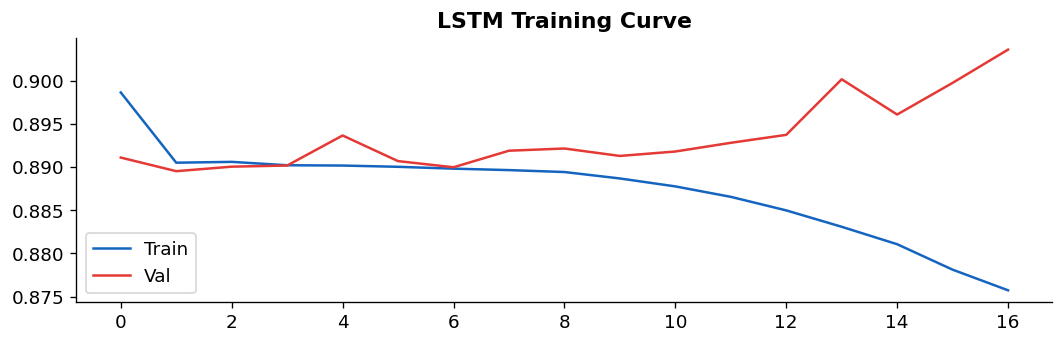

In [21]:
print('── LSTM ─────────────────────────────────────────────────────────')
if TORCH_OK:
    SEQ = 10

    def build_seqs(Xa, ya, s):
        Xs, ys = [], []
        for i in range(len(Xa) - s):
            Xs.append(Xa[i:i+s])
            ys.append(ya[i+s])
        return np.array(Xs, dtype=np.float32), np.array(ys, dtype=np.float32)

    Xs_tr, ys_tr = build_seqs(X_tr.values, np.array(y_train, dtype=float), SEQ)
    Xs_va, ys_va = build_seqs(X_va.values, np.array(y_val,   dtype=float), SEQ)

    if len(Xs_tr) < 50:
        print('  Not enough rows for LSTM sequences — skipped.')
    else:
        print(f'  Sequence shape: {Xs_tr.shape}  →  targets: {ys_tr.shape}')

        Xst = torch.tensor(Xs_tr).to(DEVICE)
        yst = torch.tensor(ys_tr).unsqueeze(1).to(DEVICE)
        Xsv = torch.tensor(Xs_va).to(DEVICE)
        ysv = torch.tensor(ys_va).unsqueeze(1).to(DEVICE)

        sl = DataLoader(TensorDataset(Xst, yst), batch_size=128, shuffle=True)

        class FishLSTM(nn.Module):
            def __init__(self, inp, hidden=64, num_layers=2):
                super().__init__()
                self.lstm = nn.LSTM(inp, hidden, num_layers,
                                    batch_first=True, dropout=0.2)
                self.fc   = nn.Sequential(
                    nn.Linear(hidden, 32), nn.ReLU(), nn.Linear(32, 1)
                )
            def forward(self, x):
                out, _ = self.lstm(x)
                return self.fc(out[:, -1, :])   # last time step only

        lstm      = FishLSTM(len(SELECTED)).to(DEVICE)
        lstm_opt  = optim.Adam(lstm.parameters(), lr=1e-3)
        lstm_crit = nn.MSELoss()

        best_vl, pat = 1e9, 0
        trl, val_l   = [], []
        t0 = time.time()

        for ep in range(100):
            # ── Train ──────────────────────────────────────────────────────────
            lstm.train()
            ep_loss = 0.0
            for Xb, yb in sl:
                lstm_opt.zero_grad()
                loss = lstm_crit(lstm(Xb), yb)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(lstm.parameters(), 1.0)
                lstm_opt.step()
                ep_loss += loss.item()
            ep_loss /= len(sl)

            # ── Validate ───────────────────────────────────────────────────────
            lstm.eval()
            with torch.no_grad():
                vl = lstm_crit(lstm(Xsv), ysv).item()

            trl.append(ep_loss)
            val_l.append(vl)

            if vl < best_vl - 1e-6:
                best_vl = vl; pat = 0
                torch.save(lstm.state_dict(), f'{OUT_DIR}/lstm_best.pt')
            else:
                pat += 1
                if pat >= 15:
                    print(f'  LSTM early stop @ epoch {ep+1}')
                    break

        lstm.load_state_dict(torch.load(f'{OUT_DIR}/lstm_best.pt', map_location=DEVICE))
        lstm.eval()
        with torch.no_grad():
            lp2 = lstm(Xsv).cpu().numpy().flatten()

        # ── Metrics — np.sqrt instead of squared=False (removed in sklearn 1.4+) ──
        lmae  = mean_absolute_error(ys_va, lp2)
        lrmse = float(np.sqrt(mean_squared_error(ys_va, lp2)))   # ← fixed
        lr2   = r2_score(ys_va, lp2)

        RESULTS.append({'model': 'LSTM', 'fit_time': round(time.time()-t0, 2),
                        'val_MAE': lmae, 'val_RMSE': lrmse, 'val_R2': lr2})
        print(f'  {"LSTM":<38}  MAE={lmae:.4f}  RMSE={lrmse:.4f}  R²={lr2:.4f}')

        # ── Loss curve ─────────────────────────────────────────────────────────
        fig, ax = plt.subplots(figsize=(9, 3))
        ax.plot(trl,   label='Train', color='#1565C0')
        ax.plot(val_l, label='Val',   color='#E53935')
        ax.set_title('LSTM Training Curve', fontweight='bold')
        ax.legend(); plt.tight_layout(); plt.show()
else:
    print('  PyTorch unavailable — skipped.')

---
## 10. 🏆 Model Comparison

In [22]:
res_df = pd.DataFrame(RESULTS)
sort_key = 'val_RMSE' if IS_REGRESSION else 'val_F1'
asc      = IS_REGRESSION
res_df   = res_df.sort_values(sort_key, ascending=asc).reset_index(drop=True)
BEST     = res_df.iloc[0]['model']

print('🏆  LEADERBOARD')
display(res_df.round(4))
print(f'\n🥇  Best model: {BEST}')

🏆  LEADERBOARD


,model,fit_time,val_Acc,val_F1,val_AUC,trn_Acc,trn_F1,trn_AUC,val_MAE,val_RMSE,val_R2
0,XGBoost,18.5300,0.9984,0.9984,1.0000,1.0000,1.0000,1.0000,NaN,NaN,NaN
1,Gradient Boosting,1393.0300,0.9983,0.9983,1.0000,0.9999,0.9999,1.0000,NaN,NaN,NaN
2,LightGBM,7.6300,0.9982,0.9982,1.0000,1.0000,1.0000,1.0000,NaN,NaN,NaN
3,Random Forest,43.0100,0.9982,0.9982,1.0000,1.0000,1.0000,1.0000,NaN,NaN,NaN
4,Extra Trees,10.4600,0.9973,0.9973,1.0000,1.0000,1.0000,1.0000,NaN,NaN,NaN
5,MLP (Neural Network),864.6400,0.9965,0.9965,1.0000,0.9973,0.9973,1.0000,NaN,NaN,NaN
6,Decision Tree,1.6000,0.9864,0.9858,0.9985,0.9860,0.9854,0.9984,NaN,NaN,NaN
7,KNN (k=7),0.1900,0.9730,0.9730,0.9961,0.9795,0.9795,0.9992,NaN,NaN,NaN
8,Logistic Regression,37.5300,0.9523,0.9523,0.9931,0.9520,0.9522,0.9934,NaN,NaN,NaN
9,LSTM,252.3900,NaN,NaN,NaN,NaN,NaN,NaN,0.8992,0.9431,-0.0001



🥇  Best model: XGBoost


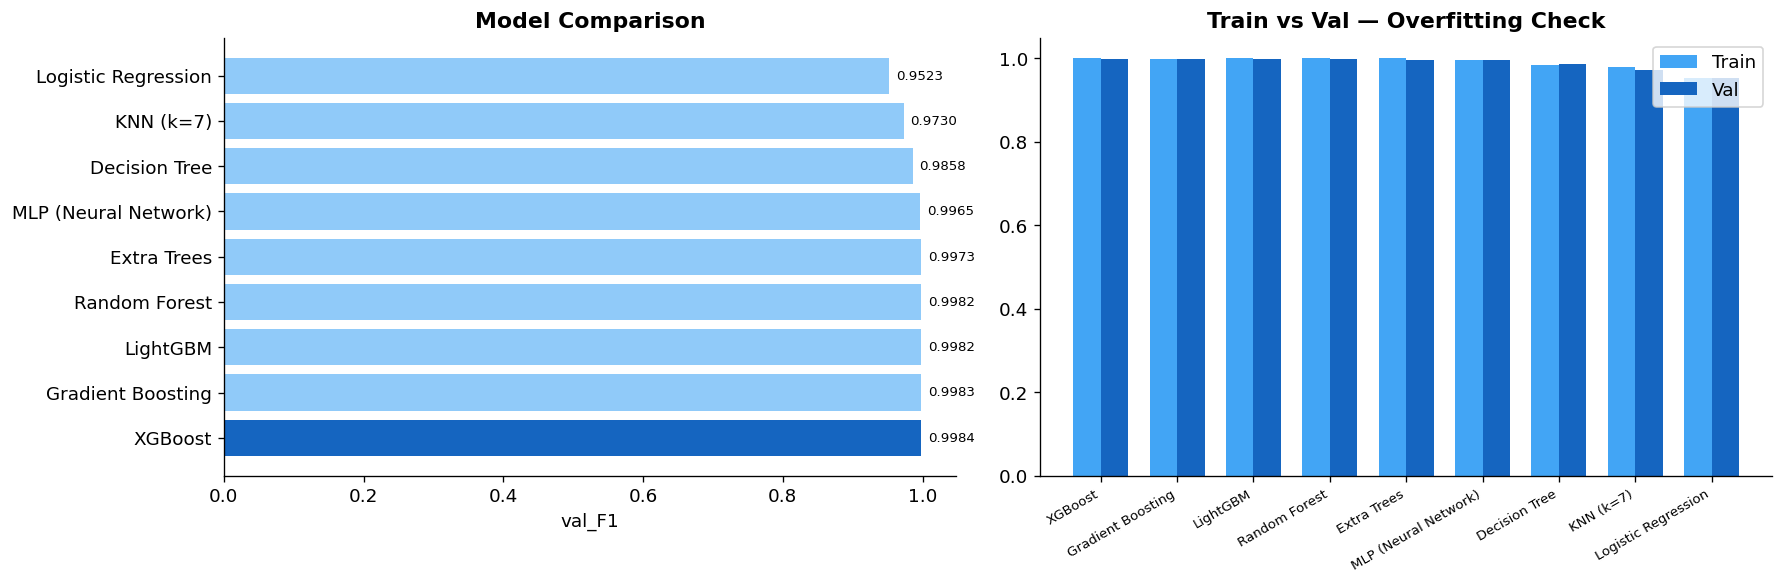

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15,5))
colors = [PALETTE[0] if m==BEST else '#90CAF9' for m in res_df['model']]

# Bar chart
bars = axes[0].barh(res_df['model'], res_df[sort_key], color=colors)
for b,v in zip(bars, res_df[sort_key]):
    axes[0].text(b.get_width()*1.01, b.get_y()+b.get_height()/2,
                 f'{v:.4f}', va='center', fontsize=8)
axes[0].set_title('Model Comparison', fontweight='bold')
axes[0].set_xlabel(sort_key)

# Train vs Val (overfitting)
trn_key = sort_key.replace('val_','trn_')
if trn_key in res_df.columns:
    sub = res_df.dropna(subset=[sort_key, trn_key])
    x   = np.arange(len(sub))
    axes[1].bar(x-.18, sub[trn_key], .36, label='Train', color='#42A5F5')
    axes[1].bar(x+.18, sub[sort_key],.36, label='Val',   color='#1565C0')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(sub['model'], rotation=30, ha='right', fontsize=8)
    axes[1].set_title('Train vs Val — Overfitting Check', fontweight='bold')
    axes[1].legend()

plt.tight_layout(); plt.show()

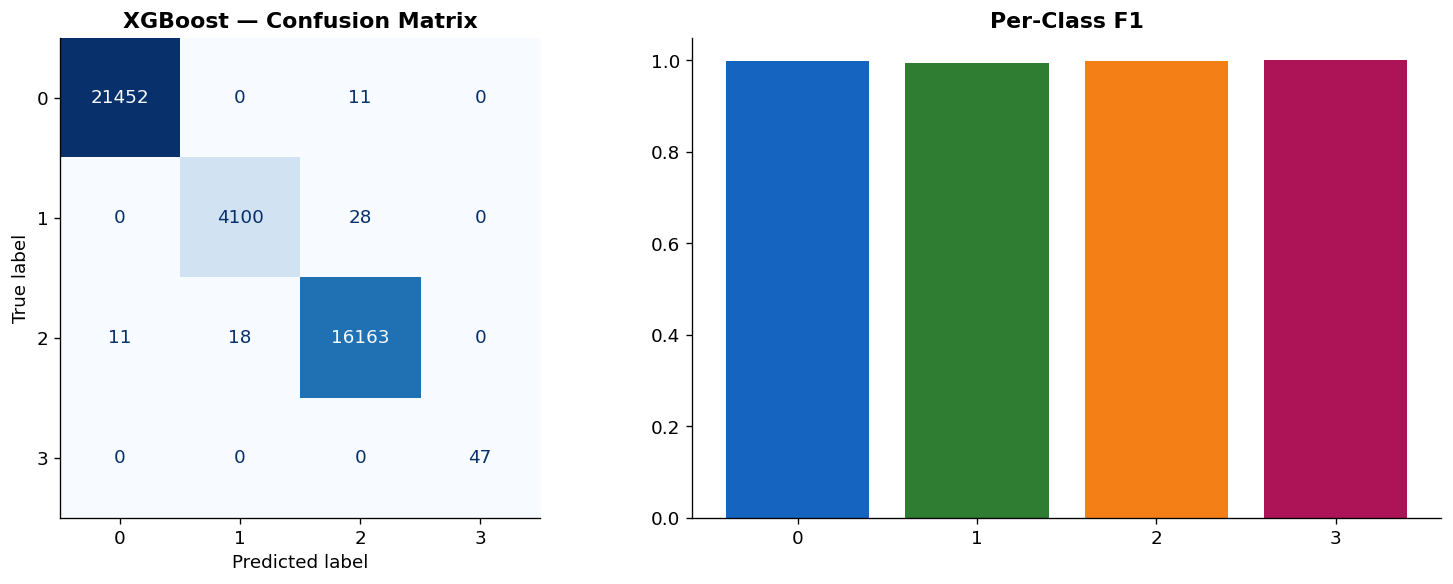

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     21463
           1       1.00      0.99      0.99      4128
           2       1.00      1.00      1.00     16192
           3       1.00      1.00      1.00        47

    accuracy                           1.00     41830
   macro avg       1.00      1.00      1.00     41830
weighted avg       1.00      1.00      1.00     41830



In [24]:
# ── Predicted vs Actual / Confusion Matrix ────────────────────────────────────
best_m = trained_models.get(BEST)
if best_m:
    yp = best_m.predict(X_va)
    if IS_REGRESSION:
        fig, axes = plt.subplots(1,2,figsize=(13,5))
        axes[0].scatter(y_val, yp, alpha=0.35, s=15, color='#1565C0')
        lims=[min(y_val.min(),yp.min()), max(y_val.max(),yp.max())]
        axes[0].plot(lims,lims,'r--',lw=1.5)
        axes[0].set_xlabel('Actual'); axes[0].set_ylabel('Predicted')
        axes[0].set_title(f'{BEST} — Predicted vs Actual', fontweight='bold')
        axes[1].scatter(yp, y_val-yp, alpha=0.35, s=15, color='#F57F17')
        axes[1].axhline(0, color='red', ls='--')
        axes[1].set_title('Residuals', fontweight='bold')
        plt.tight_layout(); plt.show()
    else:
        fig, axes = plt.subplots(1,2,figsize=(13,5))
        ConfusionMatrixDisplay(confusion_matrix(y_val,yp)).plot(ax=axes[0], cmap='Blues', colorbar=False)
        axes[0].set_title(f'{BEST} — Confusion Matrix', fontweight='bold')
        rep = pd.DataFrame(classification_report(y_val,yp,output_dict=True)).T
        rep = rep.drop(index=[c for c in ['accuracy','macro avg','weighted avg'] if c in rep.index])
        axes[1].bar(rep.index.astype(str), rep['f1-score'], color=PALETTE)
        axes[1].set_title('Per-Class F1', fontweight='bold')
        plt.tight_layout(); plt.show()
        print(classification_report(y_val, yp))

---
## 11. ⚙️ Hyperparameter Tuning (Optuna)

In [25]:
if OPTUNA_OK and BEST in ['XGBoost','LightGBM','Random Forest','Extra Trees']:

    def score(m):
        p = m.predict(X_va)
        return mean_squared_error(y_val,p,squared=False) if IS_REGRESSION \
               else -f1_score(y_val,p,average='weighted')

    def trial_xgb(t):
        p=dict(n_estimators=t.suggest_int('n',100,800),
               max_depth=t.suggest_int('d',3,10),
               learning_rate=t.suggest_float('lr',0.01,0.3,log=True),
               subsample=t.suggest_float('sub',0.5,1.0),
               colsample_bytree=t.suggest_float('col',0.5,1.0),
               random_state=42, verbosity=0, tree_method='hist')
        cls = xgb.XGBRegressor if IS_REGRESSION else xgb.XGBClassifier
        m=cls(**p); m.fit(X_tr,y_train); return score(m)

    def trial_lgb(t):
        p=dict(n_estimators=t.suggest_int('n',100,800),
               num_leaves=t.suggest_int('nl',20,150),
               learning_rate=t.suggest_float('lr',0.01,0.3,log=True),
               subsample=t.suggest_float('sub',0.5,1.0),
               colsample_bytree=t.suggest_float('col',0.5,1.0),
               random_state=42, verbose=-1, n_jobs=-1)
        cls = lgb.LGBMRegressor if IS_REGRESSION else lgb.LGBMClassifier
        m=cls(**p); m.fit(X_tr,y_train,callbacks=[lgb.log_evaluation(-1)]); return score(m)

    def trial_rf(t):
        p=dict(n_estimators=t.suggest_int('n',100,500),
               max_depth=t.suggest_int('d',5,30),
               min_samples_leaf=t.suggest_int('ml',1,10),
               max_features=t.suggest_categorical('mf',['sqrt','log2',0.5,0.8]),
               random_state=42, n_jobs=-1)
        cls = RandomForestRegressor if IS_REGRESSION else RandomForestClassifier
        m=cls(**p); m.fit(X_tr,y_train); return score(m)

    fn_map = {'XGBoost':trial_xgb,'LightGBM':trial_lgb,
              'Random Forest':trial_rf,'Extra Trees':trial_rf}
    study = optuna.create_study(direction='minimize')
    study.optimize(fn_map[BEST], n_trials=50, timeout=300, show_progress_bar=True)

    bp = study.best_params
    print(f'\n✅  Best params: {bp}')

    if BEST == 'XGBoost' and XGB_OK:
        cls = xgb.XGBRegressor if IS_REGRESSION else xgb.XGBClassifier
        tuned = cls(**bp, random_state=42, verbosity=0, tree_method='hist')
    elif BEST == 'LightGBM' and LGB_OK:
        cls = lgb.LGBMRegressor if IS_REGRESSION else lgb.LGBMClassifier
        tuned = cls(**bp, random_state=42, verbose=-1)
    else:
        cls = RandomForestRegressor if IS_REGRESSION else RandomForestClassifier
        tuned = cls(**bp, random_state=42)

    t0=time.time(); tuned.fit(X_tr,y_train); register(f'{BEST} (Tuned)', tuned, time.time()-t0)
    BEST = f'{BEST} (Tuned)'

elif not OPTUNA_OK:
    print('ℹ️  Install optuna: pip install optuna')
else:
    print(f'ℹ️  Tuning not set up for: {BEST}')

  0%|          | 0/50 [00:00<?, ?it/s]


✅  Best params: {'n': 379, 'd': 8, 'lr': 0.030268228400149973, 'sub': 0.9915699964635131, 'col': 0.6777226796507543}
  XGBoost (Tuned)                         Acc=0.9982  F1=0.9982  AUC=1.0000  (3.2s)


---
## 12. 🔍 SHAP Explainability

⚠️  SHAP TreeExplainer failed: 'str' object is not callable


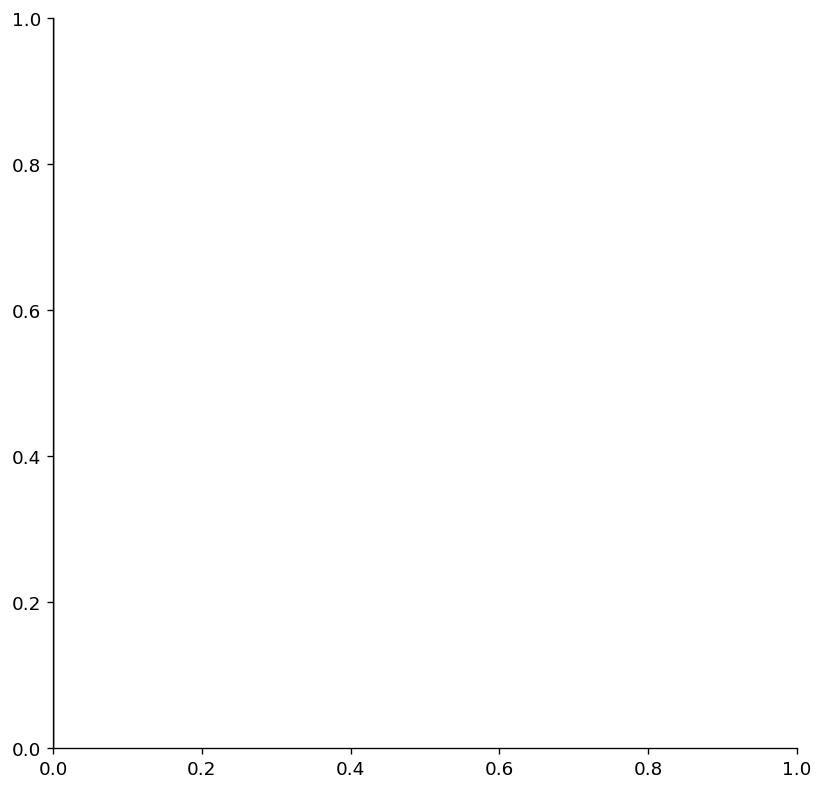

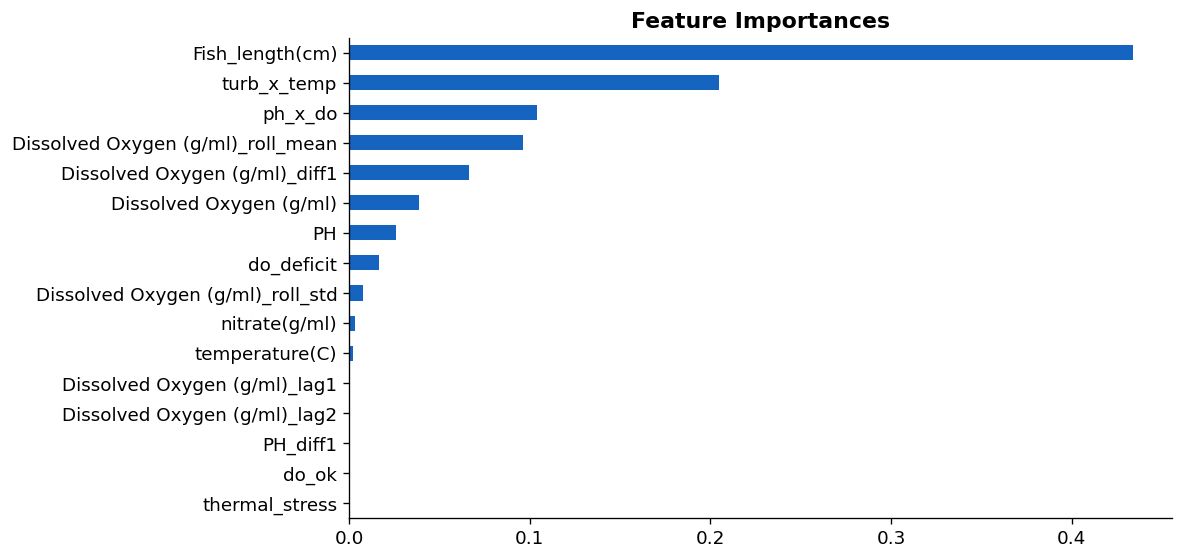

In [26]:
explain_m = trained_models.get(BEST) or trained_models.get('Random Forest')

if SHAP_OK and explain_m and hasattr(explain_m, 'feature_importances_'):
    try:
        explainer = shap.TreeExplainer(explain_m)
        sv = explainer.shap_values(X_va.values)
        if isinstance(sv, list): sv = sv[1]

        plt.figure(figsize=(10,6))
        shap.summary_plot(sv, X_va, feature_names=SELECTED,
                          plot_type='bar', show=False, color='#1565C0')
        plt.title('SHAP Feature Importance', fontweight='bold')
        plt.tight_layout(); plt.show()

        plt.figure(figsize=(10,7))
        shap.summary_plot(sv, X_va, feature_names=SELECTED, show=False)
        plt.title('SHAP Beeswarm', fontweight='bold')
        plt.tight_layout(); plt.show()

    except Exception as e:
        print(f'⚠️  SHAP TreeExplainer failed: {e}')

# sklearn fallback
if explain_m and hasattr(explain_m, 'feature_importances_'):
    fi = pd.Series(explain_m.feature_importances_, index=SELECTED).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(10, max(4,len(fi)*0.3)))
    fi.plot(kind='barh', ax=ax, color='#1565C0'); ax.invert_yaxis()
    ax.set_title('Feature Importances', fontweight='bold')
    plt.tight_layout(); plt.show()

---
## 13. 🎣 Recommendation Engine

In [27]:
class FishFeedingAdvisor:
    THR = dict(temp_lo=20,temp_hi=28,temp_crit_lo=12,temp_crit_hi=35,
               do_min=5,do_crit=3,ph_min=6.5,ph_max=8.5,turb_max=30,ammo_tox=0.02)
    MSG = {'STOP'    :'⛔  Do NOT feed — critical conditions. Immediate action needed.',
           'REDUCE'  :'⚠️  Reduce feeding 30–50%. Suboptimal conditions.',
           'NORMAL'  :'✅  Normal feeding recommended.',
           'INCREASE':'🆙  Excellent conditions — slight increase (+10%) possible.'}
    MULT= {'STOP':0.0,'REDUCE':0.55,'NORMAL':1.0,'INCREASE':1.10}

    def __init__(self, model, features):
        self.model=model; self.features=features

    def _strategy(self, e):
        T=self.THR
        t=e.get('temperature',25); d=e.get('dissolved_o2',7)
        p=e.get('ph',7);           u=e.get('turbidity',10); a=e.get('ammonia',0.005)
        if t<T['temp_crit_lo'] or t>T['temp_crit_hi'] or d<T['do_crit'] or a>T['ammo_tox']*3:
            return 'STOP'
        if (t<T['temp_lo'] or t>T['temp_hi'] or d<T['do_min'] or
                p<T['ph_min'] or p>T['ph_max'] or u>T['turb_max'] or a>T['ammo_tox']):
            return 'REDUCE'
        if T['temp_lo']+2<=t<=T['temp_hi']-2 and d>=7 and 6.8<=p<=8.0 and u<10:
            return 'INCREASE'
        return 'NORMAL'

    def recommend(self, env, base_feed_kg=None):
        strategy = self._strategy(env)
        fv = np.zeros(len(self.features))
        for i,f in enumerate(self.features):
            for k,v in env.items():
                if k.lower() in f.lower() or f.lower() in k.lower(): fv[i]=v; break
        try:   ml_pred = float(self.model.predict(pd.DataFrame([fv], columns=self.features))[0])
        except: ml_pred = None
        mult = self.MULT[strategy]
        rec  = (base_feed_kg or (ml_pred if IS_REGRESSION and ml_pred else 5.0)) * mult
        print(f'\n{"─"*52}\n  🐟  FISH FEEDING RECOMMENDATION\n{"─"*52}')
        for k,v in env.items(): print(f'  {k:<20}: {v}')
        print(f'  {"─"*48}\n  Strategy: {strategy}\n  {self.MSG[strategy]}')
        if ml_pred: print(f'  ML Prediction    : {ml_pred:.4f}')
        print(f'  Recommended feed : {rec:.3f} kg\n{"─"*52}')
        return {'strategy':strategy,'recommended_kg':rec,'ml_pred':ml_pred}

# Instantiate
best_m_final = trained_models.get(BEST) or list(trained_models.values())[0]
advisor = FishFeedingAdvisor(best_m_final, SELECTED)

for sc in [
    {'name':'Optimal',  'env':{'temperature':24.5,'dissolved_o2':7.8,'ph':7.2,'turbidity':8, 'ammonia':0.003},'kg':5},
    {'name':'Low O₂',   'env':{'temperature':30,  'dissolved_o2':4.2,'ph':7.0,'turbidity':20,'ammonia':0.010},'kg':5},
    {'name':'Critical', 'env':{'temperature':11,  'dissolved_o2':2.5,'ph':5.8,'turbidity':45,'ammonia':0.080},'kg':5},
]:
    print(f'\n🔷  {sc["name"]}')
    advisor.recommend(sc['env'], base_feed_kg=sc['kg'])


🔷  Optimal

────────────────────────────────────────────────────
  🐟  FISH FEEDING RECOMMENDATION
────────────────────────────────────────────────────
  temperature         : 24.5
  dissolved_o2        : 7.8
  ph                  : 7.2
  turbidity           : 8
  ammonia             : 0.003
  ────────────────────────────────────────────────
  Strategy: INCREASE
  🆙  Excellent conditions — slight increase (+10%) possible.
  Recommended feed : 5.500 kg
────────────────────────────────────────────────────

🔷  Low O₂

────────────────────────────────────────────────────
  🐟  FISH FEEDING RECOMMENDATION
────────────────────────────────────────────────────
  temperature         : 30
  dissolved_o2        : 4.2
  ph                  : 7.0
  turbidity           : 20
  ammonia             : 0.01
  ────────────────────────────────────────────────
  Strategy: REDUCE
  ⚠️  Reduce feeding 30–50%. Suboptimal conditions.
  Recommended feed : 2.750 kg
─────────────────────────────────────────────────

---
## 14. 📊 Final Test Evaluation & Save

In [28]:
# ── Final test evaluation ─────────────────────────────────────────────────────
if best_m_final:
    tm = evaluate(best_m_final, X_te, y_test)
    print('='*52)
    print(f'  FINAL TEST SET  |  Model: {BEST}')
    print('='*52)
    for k,v in tm.items(): print(f'  {k:<10}: {v:.5f}')
    print('='*52)

  FINAL TEST SET  |  Model: XGBoost (Tuned)
  Acc       : 0.99852
  F1        : 0.99852
  AUC       : 0.99999


In [29]:
# ── Save everything ───────────────────────────────────────────────────────────
os.makedirs(f'{OUT_DIR}/models', exist_ok=True)

# Best model
try:
    with open(f'{OUT_DIR}/models/best_model.pkl','wb') as f: pickle.dump(best_m_final,f)
    print('✅  best_model.pkl')
except Exception as e: print(f'⚠️  pickle: {e}')

if XGB_OK and hasattr(best_m_final,'save_model'):
    best_m_final.save_model(f'{OUT_DIR}/models/best_xgb.json')
    print('✅  best_xgb.json')

if LGB_OK and hasattr(best_m_final,'booster_'):
    best_m_final.booster_.save_model(f'{OUT_DIR}/models/best_lgb.txt')
    print('✅  best_lgb.txt')

# Scaler
with open(f'{OUT_DIR}/models/scaler.pkl','wb') as f: pickle.dump(scaler,f)
print('✅  scaler.pkl')

# Feature list
with open(f'{OUT_DIR}/models/features.txt','w') as f: f.write('\n'.join(SELECTED))
print(f'✅  features.txt  ({len(SELECTED)} features)')

# Cleaned engineered dataset
df.to_csv(f'{OUT_DIR}/dataset_final.csv', index=False)
print('✅  dataset_final.csv')

# Leaderboard
res_df.to_csv(f'{OUT_DIR}/leaderboard.csv', index=False)
print('✅  leaderboard.csv')

# Metrics JSON
with open(f'{OUT_DIR}/models/final_metrics.json','w') as f:
    json.dump({'model':BEST,'task':TASK,'features':SELECTED,
               'test_metrics': {k:round(float(v),5) for k,v in tm.items()}}, f, indent=2)
print('✅  final_metrics.json')

print(f'\n📂  All files saved to: {OUT_DIR}')

✅  best_model.pkl
✅  best_xgb.json
✅  scaler.pkl
✅  features.txt  (16 features)
✅  dataset_final.csv
✅  leaderboard.csv
✅  final_metrics.json

📂  All files saved to: /kaggle/working


---
## ✅ Project Checklist

| Task | Status |
|------|--------|
| Data loading & concatenation | ✅ |
| Data audit & EDA | ✅ |
| Cleaning (duplicates, outliers, imputation) | ✅ |
| Feature engineering (WQI, stress indices, lag/rolling) | ✅ |
| Feature selection (variance, correlation, MI) | ✅ |
| Train/val/test splits + RobustScaler | ✅ |
| Baseline models | ✅ |
| Ensemble models (RF, ET, GBM) | ✅ |
| XGBoost + LightGBM | ✅ |
| MLP neural network | ✅ |
| LSTM time-series model | ✅ |
| Model leaderboard & visualisations | ✅ |
| Optuna hyperparameter tuning | ✅ |
| SHAP explainability | ✅ |
| Rule-based + ML recommendation engine | ✅ |
| Final test evaluation | ✅ |
| Model & artefact persistence | ✅ |